# sms_tests — the sms_v2 benchmark, one cell per model

Same benchmark, setup and Drive layout as `colab.ipynb`, but **every model and every experiment has its own
cell**: run exactly the ones you want, in any order, each with its own settings. There are no model lists
to edit. Results land in the same Drive folder, so the two notebooks can be mixed freely.

Runs on a Colab **T4**:

| stage | what | models |
|---|---|---|
| Stage 1 | is this SMS a successful transaction? Experiment **A** binary, **B** 6-class | TF-IDF + LR / Linear SVM / Multinomial NB, MARBERT, AraBERT, XLM-RoBERTa, v1's own gate (reference) |
| Stage 2 | extract amount, currency, counterparty, date, direction, account, … | the existing v1 parser, unchanged |
| End to end | Stage 1 errors counted as missed / false records | every finished classifier |

**Runtime → Change runtime type → T4 GPU** before you start.

**Reliability.** Everything the benchmark produces goes to Google Drive. Every run writes a `DONE.json`
marker last; a finished run is **skipped** on re-run, never overwritten unless `OVERWRITE = True`. Transformers
checkpoint **after every epoch** to the VM's local disk and copy that state to Drive (`DRIVE_ROOT/resume/`).
**After a disconnect (or a restarted runtime): run sections 0 and 1, then any section you want** — or simply
Run all. Section 1 restores everything the later cells need. A transformer run continues from the newest copy that verifies —
local if the VM survived, otherwise Drive, falling back to the previous epoch if the last Drive copy never
finished uploading. Each transformer trains in its **own process**, so its GPU memory is fully released before
the next.

Splits, labels and results are documented in `sms_v2/BENCHMARK.md`.

##Summary

In [ ]:
# What is done so far: read-only, reads Drive only (no setup, no code download needed; mounts Drive if needed)
import os, json, glob
import pandas as pd
from IPython.display import display, Markdown
from google.colab import drive
if not os.path.ismount('/content/drive'):
    drive.mount('/content/drive')
ROOT = globals().get('DRIVE_ROOT', '/content/drive/MyDrive/masroofy_sms_v2')
OUT = os.path.join(ROOT, 'outputs')
SPL = globals().get('SPLIT', 'template')
RES = os.path.join(OUT, 'results', SPL)
MODELS = ['tfidf_lr', 'tfidf_svm', 'tfidf_nb', 'v1_gate', 'marbert', 'arabert', 'xlm_roberta']
EXPS = ['binary', 'multiclass']
print('results folder:', RES, '(exists)' if os.path.isdir(RES) else '(MISSING)')

# last log event per run: tells finished / failed / interrupted / still running apart
last = {}
logf = os.path.join(OUT, 'experiment_log.jsonl')
if os.path.exists(logf):
    for l in open(logf, encoding='utf-8'):
        if l.strip():
            e = json.loads(l)
            if e.get('split') == SPL:
                last[(e.get('kind'), e.get('experiment'), e.get('model'))] = e

def rd(p):
    return json.load(open(p, encoding='utf-8')) if os.path.exists(p) else None

# ---- Stage 1 classifiers
rows = []
for exp in EXPS:
    for m in MODELS:
        if m == 'v1_gate' and exp == 'multiclass':
            continue
        d = os.path.join(RES, exp, m)
        met = rd(os.path.join(d, 'metrics.json')) if os.path.exists(os.path.join(d, 'DONE.json')) else None
        e = last.get(('classify', exp, m))
        if met:
            t, r = met['test'], met['test']['routing']
            tr = met.get('train', {})
            ep = f"best {tr['best_epoch']} of {tr.get('epochs_run')}" if 'best_epoch' in tr else ''
            rows.append(dict(experiment=exp, model=m, status='DONE', test_macro_f1=round(t['macro_f1'], 3),
                             tx_precision=round(r['transaction_precision'], 3),
                             tx_recall=round(r['transaction_recall'], 3), tx_f1=round(r['transaction_f1'], 3),
                             missed_tx=r['missed_transactions'], false_tx=r['false_transactions'],
                             train_min=round((tr.get('train_time_s') or 0) / 60, 1),
                             epochs=ep, finished=met.get('finished', '')))
        else:
            st = 'not started' if e is None else {'start': 'RUNNING or INTERRUPTED', 'failed': 'FAILED',
                                                  'interrupted': 'INTERRUPTED'}.get(e['event'], e['event'])
            rows.append(dict(experiment=exp, model=m, status=st, finished=(e or {}).get('time', ''),
                             error=str((e or {}).get('error', ''))[:120]))
cls = pd.DataFrame(rows)
for c in ('missed_tx', 'false_tx'):
    cls[c] = cls[c].map(lambda v: '' if pd.isna(v) else int(v))
cls = cls.fillna('')
display(Markdown(f'### Stage 1 classifiers: split `{SPL}`'))
display(cls)
n_done = (cls.status == 'DONE').sum()
print(f'{n_done} of {len(cls)} classifier runs finished')

# ---- Stage 2 extraction + end to end
ex = rd(os.path.join(RES, 'extraction', 'metrics.json'))
display(Markdown('### Stage 2 extraction'))
print('DONE' if ex and os.path.exists(os.path.join(RES, 'extraction', 'DONE.json')) else 'not done',
      '' if not ex else f"- {ex.get('n_test_gold_transactions')} gold transactions, "
                        f"{ex.get('no_record_on_gold_transactions')} without a record")
e2e = []
for f in sorted(glob.glob(os.path.join(RES, 'end_to_end', '*', '*', 'metrics.json'))):
    if os.path.exists(os.path.join(os.path.dirname(f), 'DONE.json')):
        m = rd(f)
        e2e.append({k: (round(v, 3) if isinstance(v, float) else v) for k, v in m.items()
                    if k in ('experiment', 'model', 'records_produced', 'correct_records', 'missed_transactions',
                             'false_records', 'e2e_full_exact_precision', 'e2e_full_exact_recall',
                             'e2e_full_exact_f1')})
display(Markdown('### End to end (Stage 1 -> Stage 2)'))
if e2e:
    e2e_df = pd.DataFrame(e2e)
    e2e_df = e2e_df[['experiment', 'model'] + [c for c in e2e_df if c not in ('experiment', 'model')]]
    display(e2e_df.sort_values('e2e_full_exact_f1', ascending=False).reset_index(drop=True))
    miss = sorted({f'{r.experiment}/{r.model}' for r in cls.itertuples() if r.status == 'DONE'} -
                  {f"{r['experiment']}/{r['model']}" for r in e2e})
    if miss:
        print('finished classifiers WITHOUT end-to-end yet (run section 6):', ', '.join(miss))
else:
    print('no end-to-end results yet (run section 6)')

# ---- transformer resume state on Drive (an unfinished run continues from here)
bk = os.path.join(ROOT, 'resume')
display(Markdown('### Transformer backups on Drive'))
if os.path.isdir(bk):
    for p in sorted(glob.glob(os.path.join(bk, '**', '*.json'), recursive=True))[:30]:
        print(os.path.relpath(p, bk))
    if not glob.glob(os.path.join(bk, '**', '*.json'), recursive=True):
        print('resume folder exists but holds no state files')
else:
    print('no resume folder: no transformer has started with the Drive backup on')
summ = os.path.join(RES, 'summary', 'REPORT.md')
print('\ncomparison report (section 7):', summ if os.path.exists(summ) else 'not written yet')

## 0. Configuration — the only cell you should need to edit

In [2]:
DRIVE_ROOT = '/content/drive/MyDrive/masroofy_sms_v2'   # results + checkpoints live here
CODE_SOURCE = 'drive'        # 'drive'  : DRIVE_ROOT/code/sms_colab.tgz  (made by `python pack_for_colab.py`)
                             # 'upload' : pick sms_colab.tgz in the browser
                             # 'git'    : clone BRANCH from REPO_URL (committed + pushed code only)
# REPO_URL = 'https://github.com/<you>/Masroofy.git'      # used when CODE_SOURCE == 'git'
# BRANCH = 'sms'

SPLIT = 'template'           # primary. 'random' (optimistic) or 'sender' (unseen bank) also exist

OVERWRITE =False # default for every model cell; each cell can also pass overwrite=True on its own
                             # True = redo a run that already finished (its old results are deleted)
# Hyperparameters are NOT set here: each transformer cell has its own `override` line.

# Disconnect protection for transformer training (see section 5a):
BACKUP_TO_DRIVE = True       # copy the resumable state to DRIVE_ROOT/resume after each epoch
BACKUP_SLOTS = 2             # 2: a disconnect DURING a backup falls back one epoch (~9 GB on Drive for XLM-R)
                             # 1: half the space; a disconnect during a backup restarts that run
BACKUP_EVERY = 1             # epochs between backups (the last epoch is always backed up)

## 1. Setup — run this after EVERY connect, reconnect or runtime restart

Nothing in Python memory survives a disconnect, so this one cell rebuilds all of it: mounts Drive, points the
benchmark at Drive (results, Drive backup) and the local disk (checkpoints), fetches the code, checks the GPU,
and defines the helpers and imports every later cell uses. It is safe to run any number of times. After it,
any section can be run on its own and in any order: everything a section needs from earlier work is read
from files on Drive, not from variables.

**Getting the code** (fetched **fresh every time this cell runs**, so after editing on your PC you just re-pack
and re-run this cell; results on Drive and checkpoints in `/content/checkpoints` are outside the code folder):

* `drive` (no commit needed): on your PC, in `sms_v2/`, run `python pack_for_colab.py` and copy the
  `sms_colab.tgz` it writes to `DRIVE_ROOT/code/` (with Google Drive for desktop:
  `python pack_for_colab.py --to "G:/My Drive/masroofy_sms_v2/code"`). Give Drive a minute to sync.
* `upload` (no commit needed): same file, picked in the browser when the cell asks.
* `git`: the code must be committed and pushed on `BRANCH`.

The printed `CODE_VERSION` (pack time, content hash, uncommitted files) is saved with every run's metrics.

Changing a hyperparameter in `config/settings.py` while a transformer run is half done makes its resume
refuse (the checkpoint belongs to the old configuration): finish it first, or re-run it with `OVERWRITE`.

In [3]:
import os, sys, json, time, glob, shutil, subprocess, importlib.util
import pandas as pd
from IPython.display import Markdown, Image, display

assert 'DRIVE_ROOT' in globals(), 'Run section 0 (configuration) first.'

# ---- Drive + where everything is written (read by config/settings.py in every bench.py process)
from google.colab import drive
if not os.path.ismount('/content/drive'):
    drive.mount('/content/drive')
os.makedirs(DRIVE_ROOT, exist_ok=True)
os.environ['SMS_V2_OUTPUT'] = os.path.join(DRIVE_ROOT, 'outputs')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
# per-epoch checkpoints on the VM's fast local disk (rewriting them on Drive every epoch would fill its Trash)
os.environ['SMS_V2_CHECKPOINTS'] = '/content/checkpoints'
if BACKUP_TO_DRIVE:
    os.environ['SMS_V2_CHECKPOINT_BACKUP'] = os.path.join(DRIVE_ROOT, 'resume')
    os.environ['SMS_V2_BACKUP_SLOTS'] = str(BACKUP_SLOTS)
    os.environ['SMS_V2_BACKUP_EVERY'] = str(BACKUP_EVERY)
else:
    os.environ.pop('SMS_V2_CHECKPOINT_BACKUP', None)

# ---- code, fresh every time
WORK = '/content/work'
os.chdir('/content')
shutil.rmtree(WORK, ignore_errors=True)
os.makedirs(WORK)
if CODE_SOURCE == 'drive':
    tgz = f'{DRIVE_ROOT}/code/sms_colab.tgz'
    if not os.path.exists(tgz):
        raise FileNotFoundError(f'{tgz} not found: run `python pack_for_colab.py` on your PC and copy '
                                'sms_colab.tgz there (or use CODE_SOURCE = "upload")')
    subprocess.run(['tar', '-xzf', tgz, '-C', WORK], check=True)
elif CODE_SOURCE == 'upload':
    from google.colab import files
    up = files.upload()
    subprocess.run(['tar', '-xzf', next(iter(up)), '-C', WORK], check=True)
elif CODE_SOURCE == 'git':
    subprocess.run(['git', 'clone', '--depth', '1', '-b', BRANCH, REPO_URL, WORK + '/repo'], check=True)
    for d in ('sms_v2', 'sms_eval_final'):
        shutil.move(f'{WORK}/repo/{d}', f'{WORK}/{d}')
else:
    raise ValueError(CODE_SOURCE)
os.chdir(f'{WORK}/sms_v2')
if f'{WORK}/sms_v2' not in sys.path:
    sys.path.insert(0, f'{WORK}/sms_v2')
for m in [m for m in sys.modules if m.split('.')[0] in ('benchmark', 'classification', 'config',
                                                         'evaluation', 'extraction', 'sms_pipeline')]:
    del sys.modules[m]                      # a re-run must import the code just fetched, not the old one

# ---- dependencies + GPU
if importlib.util.find_spec('transformers') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'transformers'], check=True)
import torch, transformers, sklearn
GPU = torch.cuda.is_available()

# ---- helpers used by the later sections
def bench(*args):
    """Run bench.py in its own process, streaming its output. -> return code."""
    p = subprocess.Popen([sys.executable, '-u', 'bench.py', *args], stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        if 'Warning' not in line and 'warnings.warn' not in line:
            print(line, end='')
    return p.wait()

ow = ['--overwrite'] if OVERWRITE else []


def run_model(model, experiment, override=None, overwrite=None):
    """Train + evaluate ONE model on ONE experiment ('binary' = A, 'multiclass' = B), in its own process.
    A finished run is skipped unless overwrite (default: OVERWRITE). override = hyperparameters for this run only,
    e.g. {'epochs': 1}; None = config/settings.py. -> exit code (0 = ok)."""
    t0 = time.time()
    args = ['classify', '--models', model, '--experiments', experiment, '--splits', SPLIT]
    if OVERWRITE if overwrite is None else overwrite:
        args.append('--overwrite')
    if override:
        args += ['--override', json.dumps(override)]
    rc = bench(*args)
    print(f'--- {SPLIT}/{experiment}/{model}: ' + ('ok' if rc == 0 else f'FAILED (exit {rc}), see above; '
          'also in experiment_log.jsonl') + f' after {(time.time() - t0) / 60:.1f} min')
    if GPU:
        print(subprocess.run(['nvidia-smi', '--query-gpu=memory.used,memory.total', '--format=csv,noheader'],
                             capture_output=True, text=True).stdout.strip(), '(GPU memory after the run)')
    if hasattr(os, 'sync'):
        os.sync()                              # push Drive writes before you close the tab
    return rc

# ---- report
ver = 'CODE_VERSION.json'
if os.path.exists(ver):
    v = json.load(open(ver))
    print(f"code        -> {v['content_hash']}  packed {v['packed']}  from {v['git_branch']} @ {v['git_commit']}"
          f"  ({len(v['uncommitted'])} uncommitted files)")
else:
    print('code        ->', subprocess.run(['git', '-C', WORK + '/repo', 'rev-parse', '--short', 'HEAD'],
                                           capture_output=True, text=True).stdout.strip() or BRANCH, '(git)')
print('results     ->', os.environ['SMS_V2_OUTPUT'])
print('checkpoints ->', os.environ['SMS_V2_CHECKPOINTS'], '(local disk)')
print('backup      ->', os.environ.get('SMS_V2_CHECKPOINT_BACKUP', 'OFF'))
print('torch', torch.__version__, '| transformers', transformers.__version__, '| sklearn', sklearn.__version__)
print('GPU         ->', torch.cuda.get_device_name(0) if GPU else
      'NONE (TF-IDF still runs; transformers would be very slow: Runtime -> Change runtime type -> T4 GPU)')
if GPU:
    free, total = torch.cuda.mem_get_info()
    print(f'VRAM {total / 2**30:.1f} GB, free {free / 2**30:.1f} GB')
done = len(glob.glob(os.path.join(os.environ['SMS_V2_OUTPUT'], 'results', '*', '*', '*', 'DONE.json')))
print(f'\nalready finished on Drive: {done} classifier runs (their cells will skip them). Ready.')

Mounted at /content/drive
code        -> e890411761e9  packed 2026-11-27T22:54:12  from sms @ 70f06bf  (18 uncommitted files)
results     -> /content/drive/MyDrive/masroofy_sms_v2/outputs
checkpoints -> /content/checkpoints (local disk)
backup      -> /content/drive/MyDrive/masroofy_sms_v2/resume
torch 2.14.1+cu130 | transformers 5.22.1 | sklearn 1.6.1
GPU         -> Tesla T4
VRAM 14.6 GB, free 14.5 GB

already finished on Drive: 13 classifier runs (their cells will skip them). Ready.


## 2. Labels, class distributions and splits

`prepare` validates the labels against the gold data, writes `data/processed/label_audit.csv` (every derived
label with the rule that produced it) and **loads** the committed split files in `data/splits/` — it does not
re-draw them, so Colab and the local machine evaluate on identical rows. A changed corpus is detected by hash.

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
!python bench.py prepare --splits $SPLIT

2200 records; labels validated; audit -> /content/work/sms_v2/data/processed/label_audit.csv
binary     {'transaction': 1449, 'non_transaction': 751}
multiclass {'transaction': 1449, 'otp': 163, 'other': 189, 'failed_transaction': 149, 'promotional': 170, 'balance_inquiry': 80}

split template: loaded existing /content/work/sms_v2/data/splits/template.json
  train n= 1541  {"balance_inquiry": 53, "failed_transaction": 76, "other": 166, "otp": 127, "promotional": 134, "transaction": 985}
  val   n=  323  {"balance_inquiry": 8, "failed_transaction": 32, "other": 15, "otp": 21, "promotional": 28, "transaction": 219}
  test  n=  336  {"balance_inquiry": 19, "failed_transaction": 41, "other": 8, "otp": 15, "promotional": 8, "transaction": 245}

report -> /content/work/sms_v2/data/processed/dataset_report.json


In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
import json, pandas as pd
rep = json.load(open('data/processed/dataset_report.json', encoding='utf-8'))
print('records:', rep['n_records'], '| data hash:', rep['data_hash'])
display(pd.Series(rep['multiclass'], name='multi-class').to_frame().join(
        pd.Series(rep['binary'], name='binary'), how='outer'))
for s, d in rep['splits'].items():
    print(f'\nsplit {s}  grouping: {d["grouping"]}')
    display(pd.DataFrame({k: v['multiclass'] for k, v in d['summary'].items()}).fillna(0).astype(int))
audit = pd.read_csv('data/processed/label_audit.csv')
print('\nhow each multi-class label was derived:')
display(audit.groupby(['label_multi', 'label_reason']).size().rename('n').reset_index()
        .sort_values(['label_multi', 'n'], ascending=[True, False]))

records: 2200 | data hash: fe332d852824f2a1


,multi-class,binary
balance_inquiry,80.0,NaN
failed_transaction,149.0,NaN
non_transaction,NaN,751.0
other,189.0,NaN
otp,163.0,NaN
promotional,170.0,NaN
transaction,1449.0,1449.0



split template  grouping: {'n_groups': 249, 'groups_before_near_dup': 249, 'near_dup_pairs': 5031, 'largest_group': 72, 'chosen_seed': 50, 'seeds_tried': 30, 'imbalance': 0.8017}


,train,val,test
transaction,985,219,245
otp,127,21,15
other,166,15,8
promotional,134,28,8
failed_transaction,76,32,41
balance_inquiry,53,8,19



how each multi-class label was derived:


,label_multi,label_reason,n
0,balance_inquiry,CATEGORY_MAP[balance],37
1,balance_inquiry,CATEGORY_MAP[vf_balance],35
2,balance_inquiry,RULES[balance_inquiry] in mixed category oc_none,8
3,failed_transaction,CATEGORY_MAP[declined],71
4,failed_transaction,CATEGORY_MAP[vf_insufficient],27
5,failed_transaction,CATEGORY_MAP[vf_wrong_pin],17
8,failed_transaction,RULES[failed_transaction] in mixed category hs...,12
7,failed_transaction,RULES[failed_transaction] in mixed category ci...,11
6,failed_transaction,RULES[failed_transaction] in mixed category bm...,7
9,failed_transaction,RULES[failed_transaction] in mixed category oc...,4


In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# keep a copy of the exact split files next to the results, for the record
import shutil, filecmp
dst = os.path.join(os.environ['SMS_V2_OUTPUT'], 'splits')
os.makedirs(dst, exist_ok=True)
for s in [SPLIT]:
    src, out = f'data/splits/{s}.json', os.path.join(dst, f'{s}.json')
    if os.path.exists(out) and not filecmp.cmp(src, out, shallow=False):
        raise RuntimeError(f'{out} differs from the repo split: results on Drive were made on another split. '
                           'Use a new DRIVE_ROOT or delete the old results deliberately.')
    shutil.copy(src, out)
print('splits recorded in', dst)

splits recorded in /content/drive/MyDrive/masroofy_sms_v2/outputs/splits


## 3. Quick tests (CPU, ~2 min)

Labels, leakage, every classifier interface, routing rules, end-to-end accounting, and the transformer train → interrupt → resume → save → load cycle on a tiny model.

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
!python -m pytest tests -q -p no:cacheprovider 2>&1 | tail -5

...........................................                              [100%]
43 passed in 213.81s (0:03:33)


## 4. Traditional baselines (CPU, seconds each)

One cell per model and experiment. Experiment **A** = binary (transaction / not), **B** = 6-class. `v1_gate` is v1's own transaction decision, binary only.

In [ ]:

assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# v1 as ONE whole model, exactly like sms_eval_final/evaluate.py does in each fold:
# SmsTxnModel().fit(train) -> predict(sms) on every test message -> evaluate.score (v1's own metrics).
# Uses the benchmark's split (train / test), CPU only, ~30-60 s. Writes nothing.
import importlib.util, json, os, sys, time
import numpy as np, pandas as pd

split = SPLIT if 'SPLIT' in globals() else SPLITS[0]          # works in sms_tests.ipynb and colab.ipynb
V1_DIR = os.path.abspath('../sms_eval_final')
if V1_DIR not in sys.path:
    sys.path.insert(0, V1_DIR)                                # evaluate.py imports sms_model from here
spec = importlib.util.spec_from_file_location('v1_evaluate', os.path.join(V1_DIR, 'evaluate.py'))
V1E = importlib.util.module_from_spec(spec); spec.loader.exec_module(V1E)   # not HF's `evaluate`

data = {r['id']: r for r in (json.loads(l) for l in open(os.path.join(V1_DIR, 'sms_dataset_2200.jsonl'),
                                                          encoding='utf-8') if l.strip())}
ids = json.load(open(f'data/splits/{split}.json', encoding='utf-8'))['ids']

t0 = time.time()
v1 = V1E.SmsTxnModel().fit([data[i] for i in ids['train']])
pairs = [(data[i], v1.predict(data[i]['sms'])) for i in ids['test']]
res, errs = V1E.score(pairs)
print(f'v1 whole: trained on {len(ids["train"])} train messages, tested on {len(pairs)} test messages '
      f'({time.time() - t0:.0f} s)')
display(pd.Series(res, name='v1 whole').to_frame().T.round(3))

cm = np.zeros((2, 2), int)
for r, p in pairs:
    cm[0 if r['expected']['is_transaction'] else 1, 0 if p['is_transaction'] else 1] += 1
display(pd.DataFrame(cm, index=['gold: transaction', 'gold: not'], columns=['pred: transaction', 'pred: not']))
print({k: len(v) for k, v in errs.items()}, '<- number of errors per field')
del v1, pairs

v1 whole: trained on 1541 train messages, tested on 336 test messages (17 s)


,n,tx_precision,tx_recall,tx_f1,non_tx_rejected,full_record_exact,type,amount,currency,fee,balance_after,merchant,channel,datetime,account_last4
v1 whole,336.0,0.857,0.784,0.819,0.648,0.31,0.714,0.979,0.979,0.943,0.927,0.807,0.938,0.911,0.927


,pred: transaction,pred: not
gold: transaction,192,53
gold: not,32,59


{'merchant': 37, 'is_transaction': 85, 'account_last4': 14, 'channel': 12, 'fee': 11, 'type': 55, 'balance_after': 14, 'datetime': 17, 'amount': 4, 'currency': 4} <- number of errors per field


### TF-IDF + Logistic Regression

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# TF-IDF + Logistic Regression — A: binary
run_model('tfidf_lr', 'binary')

=== template / binary / tfidf_lr: 1541 train, 323 val, 336 test
    test macro-F1 0.7068  acc 0.7827  tx recall 0.8857  tx precision 0.8282  | 0.32 ms/SMS
--- template/binary/tfidf_lr: ok after 0.2 min
105 MiB, 15360 MiB (GPU memory after the run)


0

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# TF-IDF + Logistic Regression — B: 6-class
run_model('tfidf_lr', 'multiclass')

=== template / multiclass / tfidf_lr: 1541 train, 323 val, 336 test
    test macro-F1 0.6444  acc 0.7649  tx recall 0.8980  tx precision 0.8088  | 0.31 ms/SMS
--- template/multiclass/tfidf_lr: ok after 0.3 min
105 MiB, 15360 MiB (GPU memory after the run)


0

### TF-IDF + Linear SVM

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# TF-IDF + Linear SVM — A: binary
run_model('tfidf_svm', 'binary')

=== template / binary / tfidf_svm: 1541 train, 323 val, 336 test
    test macro-F1 0.6963  acc 0.7768  tx recall 0.8857  tx precision 0.8220  | 0.56 ms/SMS
--- template/binary/tfidf_svm: ok after 0.2 min
105 MiB, 15360 MiB (GPU memory after the run)


0

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# TF-IDF + Linear SVM — B: 6-class
run_model('tfidf_svm', 'multiclass')

=== template / multiclass / tfidf_svm: 1541 train, 323 val, 336 test
    test macro-F1 0.7396  acc 0.8274  tx recall 0.9592  tx precision 0.8304  | 0.33 ms/SMS
--- template/multiclass/tfidf_svm: ok after 0.2 min
105 MiB, 15360 MiB (GPU memory after the run)


0

### TF-IDF + Multinomial Naive Bayes

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# TF-IDF + Multinomial Naive Bayes — A: binary
run_model('tfidf_nb', 'binary')

=== template / binary / tfidf_nb: 1541 train, 323 val, 336 test
    test macro-F1 0.6508  acc 0.7381  tx recall 0.8490  tx precision 0.8031  | 0.31 ms/SMS
--- template/binary/tfidf_nb: ok after 0.1 min
105 MiB, 15360 MiB (GPU memory after the run)


0

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# TF-IDF + Multinomial Naive Bayes — B: 6-class
run_model('tfidf_nb', 'multiclass')

=== template / multiclass / tfidf_nb: 1541 train, 323 val, 336 test
    test macro-F1 0.5204  acc 0.6637  tx recall 0.7633  tx precision 0.8238  | 0.61 ms/SMS
--- template/multiclass/tfidf_nb: ok after 0.2 min
105 MiB, 15360 MiB (GPU memory after the run)


0

### v1 gate (reference)

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# v1 gate (reference) — A: binary
run_model('v1_gate', 'binary')

=== template / binary / v1_gate: 1541 train, 323 val, 336 test
    test macro-F1 0.7000  acc 0.7470  tx recall 0.7837  tx precision 0.8571  | 7.19 ms/SMS
--- template/binary/v1_gate: ok after 0.5 min
105 MiB, 15360 MiB (GPU memory after the run)


0

## 5. Transformers, one at a time

One cell per model and experiment; **run one cell at a time**. Each run is a **separate process**: when it ends,
all of its GPU memory is returned. Interrupted? Run sections 0 and 1, then re-run the same cell: a finished
run is skipped and an interrupted one resumes from its newest saved epoch (local disk, or the Drive backup
if the VM was lost).

Each cell has its own `override` line: `None` = the settings in `config/settings.py` (`TRANSFORMER_DEFAULTS`:
max epochs, early-stopping patience, learning rate, batch size; XLM-R has its own lr); e.g. `{'epochs': 1}` for a quick test of that one run. A run
finished with an override is **skipped** later — pass `overwrite=True` in that cell once to redo it. Changing
`override` while a run is half finished makes its resume refuse (different configuration).

Roughly 1–3 min per epoch per model on a T4 with ~1.5k training messages; XLM-R is the slowest.

### 5a. Backup slots and Drive space

What the Drive backup holds right now. After a disconnect, a slot in state `ok` is what the interrupted run
continues from; `free` slots belong to finished runs and are overwritten by the next one (never deleted, so
nothing lands in Drive's Trash). If the free-space line drops below ~10 GB, set `BACKUP_SLOTS = 1`.

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
import shutil, pandas as pd
from classification.checkpoint_backup import describe
u = shutil.disk_usage('/content/drive/MyDrive')
print(f'Drive: {u.free / 2**30:.1f} GB free of {u.total / 2**30:.1f} GB (as reported by the Drive mount)')
u = shutil.disk_usage('/content')
print(f'VM disk: {u.free / 2**30:.1f} GB free')
if os.environ.get('SMS_V2_CHECKPOINT_BACKUP'):
    display(pd.DataFrame(describe(os.environ['SMS_V2_CHECKPOINT_BACKUP'], BACKUP_SLOTS)))
else:
    print('Drive backup is OFF: a lost VM restarts an unfinished transformer run from epoch 0.')

Drive: 103.9 GB free of 112.6 GB (as reported by the Drive mount)
VM disk: 109.4 GB free


,slot,state,run,epoch,best_epoch,size_mb,written
0,0,free,None,None,None,0,None
1,1,empty,None,None,None,0,None


### 5 · MARBERT

`UBC-NLP/MARBERT` — dialectal Arabic, 163M parameters

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# MARBERT — A: binary
override = None      # e.g. {'epochs': 1} for a quick test; None = config/settings.py
run_model('marbert', 'binary', override)

=== template / binary / marbert: 1541 train, 323 val, 336 test

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 15433.92it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: UBC-NLP/MARBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architect

0

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# MARBERT — B: 6-class
override = None      # e.g. {'epochs': 1} for a quick test; None = config/settings.py
run_model('marbert', 'multiclass', override)

=== template / multiclass / marbert: 1541 train, 323 val, 336 test

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8682.59it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: UBC-NLP/MARBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

0

### 5 · AraBERT

`aubmindlab/bert-base-arabertv02` — formal Arabic, 135M

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# AraBERT — A: binary
override = None      # e.g. {'epochs': 1} for a quick test; None = config/settings.py
run_model('arabert', 'binary', override)

=== template / binary / arabert: 1541 train, 323 val, 336 test

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3807.35it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- 

0

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# AraBERT — B: 6-class
override = None      # e.g. {'epochs': 1} for a quick test; None = config/settings.py
run_model('arabert', 'multiclass', override)

=== template / multiclass / arabert: 1541 train, 323 val, 336 test

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 728.87it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.

0

### 5 · XLM-RoBERTa

`FacebookAI/xlm-roberta-base` — multilingual, 278M; slowest, lr 2e-5

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# XLM-RoBERTa — A: binary
override = None      # e.g. {'epochs': 1} for a quick test; None = config/settings.py
run_model('xlm_roberta', 'binary', override)

=== template / binary / xlm_roberta: 1541 train, 323 val, 336 test

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 4978.72it/s]
[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the c

0

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# XLM-RoBERTa — B: 6-class
override = None      # e.g. {'epochs': 1} for a quick test; None = config/settings.py
run_model('xlm_roberta', 'multiclass', override)

=== template / multiclass / xlm_roberta: 1541 train, 323 val, 336 test

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 843.79it/s]
[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

0

## 6. Standalone extraction, then the end-to-end pipeline

Extraction is fitted on the training split and scored on gold transactions only (a perfect Stage 1). End to end then counts every Stage-1 miss and false accept.

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# standalone extraction (v1 extractor fitted on the training split)
bench('extract', '--splits', SPLIT, *ow)

skip extraction/template: already complete. Pass --overwrite to redo it.


0

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# end to end for every classifier finished so far (re-run after training more models; cached results reused)
bench('e2e', '--splits', SPLIT, '--experiments', 'binary,multiclass')

  e2e binary/tfidf_lr: inputs changed since last run, recomputing
  e2e binary     tfidf_lr     exact-record F1 0.300  missed  28  false records  45  8.38 ms/SMS
  e2e binary/tfidf_svm: inputs changed since last run, recomputing
  e2e binary     tfidf_svm    exact-record F1 0.299  missed  28  false records  47  8.68 ms/SMS
  e2e binary/tfidf_nb: inputs changed since last run, recomputing
  e2e binary     tfidf_nb     exact-record F1 0.302  missed  37  false records  51  8.27 ms/SMS
  e2e binary/marbert: inputs changed since last run, recomputing
  e2e binary     marbert      exact-record F1 0.283  missed   7  false records   4  8.72 ms/SMS
  e2e binary/arabert: inputs changed since last run, recomputing
  e2e binary     arabert      exact-record F1 0.304  missed   0  false records  10  9.03 ms/SMS
  e2e binary/xlm_roberta: inputs changed since last run, recomputing
  e2e binary     xlm_roberta  exact-record F1 0.300  missed   2  false records   6  8.93 ms/SMS
  e2e binary/v1_gate: inpu

0

## 7. Comparison tables and charts

Written to `outputs/results/<split>/summary/` on Drive: CSV + JSON tables, `REPORT.md`, `charts/`, `confusion_matrices/`.

summary for template: 13 classifier runs, 14 e2e rows, 23 charts -> /content/drive/MyDrive/masroofy_sms_v2/outputs/results/template/summary


# Stage-1 benchmark — split `template`
Generated 2026-11-27T04:56:36 from the saved runs under `/content/drive/MyDrive/masroofy_sms_v2/outputs`. Every number is on the untouched TEST set unless the column says `val`.
## Data
| side | n | transaction | balance_inquiry | otp | promotional | failed_transaction | other |
|---|---|---|---|---|---|---|---|
| train | 1541 | 985 | 53 | 127 | 134 | 76 | 166 |
| val | 323 | 219 | 8 | 21 | 28 | 32 | 15 |
| test | 336 | 245 | 19 | 15 | 8 | 41 | 8 |

Grouping: {"n_groups": 249, "groups_before_near_dup": 249, "near_dup_pairs": 5031, "largest_group": 72, "chosen_seed": 50, "seeds_tried": 30, "imbalance": 0.8017}

## Classification
Intervals are 95% bootstrap over TEMPLATE groups (see compare_models.py).

| experiment | model | accuracy | macro_f1 | macro_f1_ci95 | weighted_f1 | transaction_recall | transaction_recall_ci95 | transaction_precision | false_accept_rate | missed_transactions | false_transactions | val_macro_f1 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| binary | tfidf_lr | 0.783 | 0.707 | 0.518–0.940 | 0.775 | 0.886 | 0.696–1.000 | 0.828 | 0.495 | 28 | 45 | 0.993 |
| binary | tfidf_svm | 0.777 | 0.696 | 0.514–0.929 | 0.768 | 0.886 | 0.696–1.000 | 0.822 | 0.516 | 28 | 47 | 0.989 |
| binary | tfidf_nb | 0.738 | 0.651 | 0.483–0.861 | 0.731 | 0.849 | 0.679–1.000 | 0.803 | 0.560 | 37 | 51 | 0.979 |
| binary | marbert | 0.967 | 0.959 | 0.882–1.000 | 0.967 | 0.971 | 0.891–1.000 | 0.983 | 0.044 | 7 | 4 | 0.996 |
| binary | arabert | 0.970 | 0.961 | 0.883–1.000 | 0.970 | 1.000 | 1.000–1.000 | 0.961 | 0.110 | 0 | 10 | 1.000 |
| binary | xlm_roberta | 0.976 | 0.969 | 0.912–1.000 | 0.976 | 0.992 | 0.969–1.000 | 0.976 | 0.066 | 2 | 6 | 1.000 |
| binary | v1_gate | 0.747 | 0.700 | 0.504–0.975 | 0.754 | 0.784 | 0.564–1.000 | 0.857 | 0.352 | 53 | 32 | 0.899 |
| multiclass | tfidf_lr | 0.765 | 0.644 | 0.436–0.803 | 0.751 | 0.898 | 0.728–1.000 | 0.809 | 0.571 | 25 | 52 | 0.686 |
| multiclass | tfidf_svm | 0.827 | 0.740 | 0.623–0.884 | 0.796 | 0.959 | 0.891–1.000 | 0.830 | 0.527 | 10 | 48 | 0.683 |
| multiclass | tfidf_nb | 0.664 | 0.520 | 0.349–0.689 | 0.681 | 0.763 | 0.511–0.995 | 0.824 | 0.440 | 58 | 40 | 0.768 |
| multiclass | marbert | 0.964 | 0.862 | 0.683–0.973 | 0.963 | 0.992 | 0.969–1.000 | 0.992 | 0.022 | 2 | 2 | 0.870 |
| multiclass | arabert | 0.985 | 0.935 | 0.748–1.000 | 0.986 | 1.000 | 1.000–1.000 | 1.000 | 0.000 | 0 | 0 | 0.865 |
| multiclass | xlm_roberta | 0.935 | 0.832 | 0.665–0.937 | 0.946 | 0.943 | 0.859–1.000 | 1.000 | 0.000 | 14 | 0 | 0.891 |

## Cost
| experiment | model | device | train_time_s | infer_ms_per_sms_batch | infer_ms_per_sms_single | model_size_mb | n_parameters | peak_gpu_mem_train_mb | score_type | selected |
|---|---|---|---|---|---|---|---|---|---|---|
| binary | tfidf_lr | cpu | 2.502 | 0.324 | 1.806 | 0.342 |  |  | probability | {'C': 1.0} |
| binary | tfidf_svm | cpu | 1.110 | 0.563 | 2.474 | 0.342 |  |  | decision_function | {'C': 0.1} |
| binary | tfidf_nb | cpu | 0.615 | 0.308 | 2.174 | 0.615 |  |  | probability | {'alpha': 0.5} |
| binary | marbert | cuda | 52.274 | 1.283 | 18.681 | 623.789 | 163M | 3250.658 | probability | {'best_epoch': 3} |
| binary | arabert | cuda | 57.069 | 1.198 | 14.538 | 517.448 | 135M | 3271.630 | probability | {'best_epoch': 3} |
| binary | xlm_roberta | cuda | 82.285 | 1.281 | 14.781 | 1076.991 | 278M | 5363.680 | probability | {'best_epoch': 4} |
| binary | v1_gate | cpu | 13.917 | 7.192 | 13.580 | 3.173 |  |  | probability |  |
| multiclass | tfidf_lr | cpu | 9.203 | 0.307 | 2.137 | 1.021 |  |  | probability | {'C': 1.0} |
| multiclass | tfidf_svm | cpu | 1.636 | 0.331 | 1.877 | 0.958 |  |  | decision_function | {'C': 0.5} |
| multiclass | tfidf_nb | cpu | 0.850 | 0.605 | 3.420 | 0.763 |  |  | probability | {'alpha': 0.5} |
| multiclass | marbert | cuda | 44.015 | 1.116 | 14.261 | 623.801 | 163M | 3250.705 | probability | {'best_epoch': 2} |
| multiclass | arabert | cuda | 57.513 | 1.381 | 23.630 | 517.460 | 135M | 3271.666 | probability | {'best_epoch': 3} |
| multiclass | xlm_roberta | cuda | 92.102 | 0.944 | 15.334 | 1077.003 | 278M | 5363.739 | probability | {'best_epoch': 5} |

## Per-class F1 (multi-class)
| model | transaction | balance_inquiry | otp | promotional | failed_transaction | other |
|---|---|---|---|---|---|---|
| tfidf_lr | 0.851 | 0.128 | 0.966 | 0.769 | 0.353 | 0.800 |
| tfidf_svm | 0.890 | 0.188 | 1.000 | 1.000 | 0.360 | 1.000 |
| tfidf_nb | 0.792 | 0.065 | 0.867 | 0.522 | 0.277 | 0.600 |
| marbert | 0.992 | 0.643 | 1.000 | 0.842 | 1.000 | 0.696 |
| arabert | 1.000 | 0.848 | 1.000 | 0.762 | 1.000 | 1.000 |
| xlm_roberta | 0.971 | 1.000 | 0.933 | 0.636 | 0.921 | 0.533 |

## Standalone extraction (perfect Stage 1, gold transactions only)
| extractor | n | amount_acc | currency_acc | counterparty_precision | counterparty_recall | counterparty_f1 | date_acc | direction_acc | account_last4_acc | core_record_exact | full_record_exact |
|---|---|---|---|---|---|---|---|---|---|---|---|
| v1_sklearn | 245 | 0.967 | 0.984 | 0.920 | 0.508 | 0.655 | 0.820 | 0.804 | 0.943 | 0.416 | 0.310 |

`reference` is extracted but not evaluated: the corpus has no gold ids.

## End-to-end (Stage-1 errors included)
Missed = gold transaction with no record; false record = non-transaction that produced one. Field accuracies are over ALL gold transactions, misses scored as wrong.

| experiment | model | missed_transactions | missed_by_stage1 | missed_by_stage2 | false_records | e2e_full_exact_recall | e2e_full_exact_precision | amount_acc | counterparty_f1 | date_acc | direction_acc | pipeline_ms_per_sms |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| oracle | oracle | 0 | 0 | 0 | 0 | 0.310 | 0.310 | 0.967 | 0.655 | 0.820 | 0.804 | 7.530 |
| binary | tfidf_lr | 28 | 28 | 0 | 45 | 0.310 | 0.290 | 0.853 | 0.655 | 0.816 | 0.690 | 8.376 |
| binary | tfidf_svm | 28 | 28 | 0 | 47 | 0.310 | 0.288 | 0.853 | 0.655 | 0.816 | 0.690 | 8.677 |
| binary | tfidf_nb | 37 | 37 | 0 | 51 | 0.310 | 0.293 | 0.816 | 0.655 | 0.816 | 0.653 | 8.268 |
| binary | marbert | 7 | 7 | 0 | 4 | 0.282 | 0.285 | 0.939 | 0.620 | 0.792 | 0.776 | 8.721 |
| binary | arabert | 0 | 0 | 0 | 10 | 0.310 | 0.298 | 0.967 | 0.655 | 0.820 | 0.804 | 9.035 |
| binary | xlm_roberta | 2 | 2 | 0 | 6 | 0.302 | 0.297 | 0.959 | 0.645 | 0.812 | 0.796 | 8.934 |
| binary | v1_gate | 53 | 53 | 0 | 32 | 0.310 | 0.339 | 0.767 | 0.655 | 0.816 | 0.624 | 14.076 |
| multiclass | tfidf_lr | 25 | 25 | 0 | 52 | 0.310 | 0.279 | 0.865 | 0.655 | 0.816 | 0.702 | 8.667 |
| multiclass | tfidf_svm | 10 | 10 | 0 | 48 | 0.310 | 0.269 | 0.927 | 0.655 | 0.820 | 0.763 | 9.029 |
| multiclass | tfidf_nb | 58 | 58 | 0 | 40 | 0.282 | 0.304 | 0.731 | 0.615 | 0.788 | 0.567 | 7.582 |
| multiclass | marbert | 2 | 2 | 0 | 2 | 0.302 | 0.302 | 0.959 | 0.645 | 0.812 | 0.796 | 8.646 |
| multiclass | arabert | 0 | 0 | 0 | 0 | 0.310 | 0.310 | 0.967 | 0.655 | 0.820 | 0.804 | 8.911 |
| multiclass | xlm_roberta | 14 | 14 | 0 | 0 | 0.298 | 0.316 | 0.927 | 0.645 | 0.816 | 0.747 | 8.044 |

## Experiment A (binary) vs B (multi-class)
| model | A_binary_tx_recall | A_binary_tx_precision | A_binary_missed | A_binary_false_records | A_binary_e2e_exact_recall | A_binary_pipeline_ms | B_multiclass_tx_recall | B_multiclass_tx_precision | B_multiclass_missed | B_multiclass_false_records | B_multiclass_e2e_exact_recall | B_multiclass_pipeline_ms |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| tfidf_lr | 0.886 | 0.828 | 28 | 45 | 0.310 | 8.376 | 0.898 | 0.809 | 25 | 52 | 0.310 | 8.667 |
| tfidf_svm | 0.886 | 0.822 | 28 | 47 | 0.310 | 8.677 | 0.959 | 0.830 | 10 | 48 | 0.310 | 9.029 |
| tfidf_nb | 0.849 | 0.803 | 37 | 51 | 0.310 | 8.268 | 0.763 | 0.824 | 58 | 40 | 0.282 | 7.582 |
| marbert | 0.971 | 0.983 | 7 | 4 | 0.282 | 8.721 | 0.992 | 0.992 | 2 | 2 | 0.302 | 8.646 |
| arabert | 1.000 | 0.961 | 0 | 10 | 0.310 | 9.035 | 1.000 | 1.000 | 0 | 0 | 0.310 | 8.911 |
| xlm_roberta | 0.992 | 0.976 | 2 | 6 | 0.302 | 8.934 | 0.943 | 1.000 | 14 | 0 | 0.298 | 8.044 |
| v1_gate | 0.784 | 0.857 | 53 | 32 | 0.310 | 14.076 |  |  |  |  |  |  |

## Run status
| kind | experiment | model | state | detail |
|---|---|---|---|---|
| classify | binary | tfidf_lr | done |  |
| classify | binary | tfidf_svm | done |  |
| classify | binary | tfidf_nb | done |  |
| classify | binary | marbert | done |  |
| classify | binary | arabert | done |  |
| classify | binary | xlm_roberta | done |  |
| classify | binary | v1_gate | done |  |
| classify | multiclass | tfidf_lr | done |  |
| classify | multiclass | tfidf_svm | done |  |
| classify | multiclass | tfidf_nb | done |  |
| classify | multiclass | marbert | done |  |
| classify | multiclass | arabert | done |  |
| classify | multiclass | xlm_roberta | done |  |
| extract | - | v1_sklearn | done |  |

## Charts
- `charts/accuracy.png`
- `charts/macro_f1.png`
- `charts/transaction_recall.png`
- `charts/transaction_precision.png`
- `charts/per_class_f1_multiclass.png`
- `charts/per_class_f1_binary.png`
- `charts/train_time_s.png`
- `charts/infer_ms_per_sms_batch.png`
- `charts/end_to_end_errors.png`
- `charts/end_to_end_exact_recall.png`
- `confusion_matrices/binary_tfidf_lr.png`
- `confusion_matrices/binary_tfidf_svm.png`
- `confusion_matrices/binary_tfidf_nb.png`
- `confusion_matrices/binary_marbert.png`
- `confusion_matrices/binary_arabert.png`
- `confusion_matrices/binary_xlm_roberta.png`
- `confusion_matrices/binary_v1_gate.png`
- `confusion_matrices/multiclass_tfidf_lr.png`
- `confusion_matrices/multiclass_tfidf_svm.png`
- `confusion_matrices/multiclass_tfidf_nb.png`
- `confusion_matrices/multiclass_marbert.png`
- `confusion_matrices/multiclass_arabert.png`
- `confusion_matrices/multiclass_xlm_roberta.png`


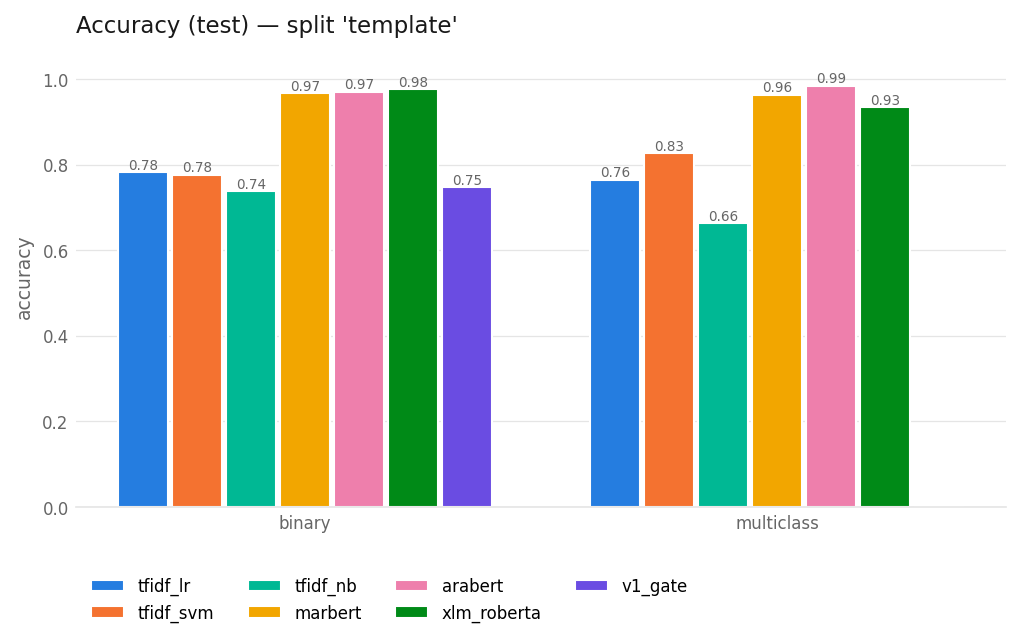

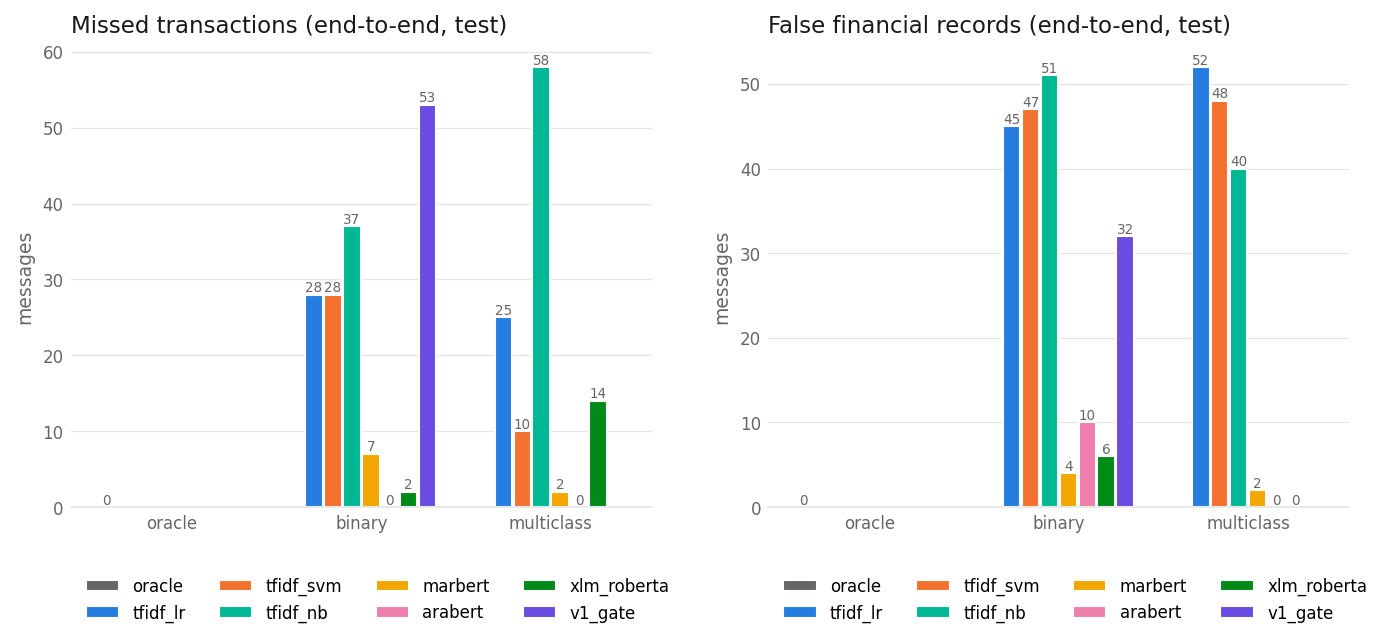

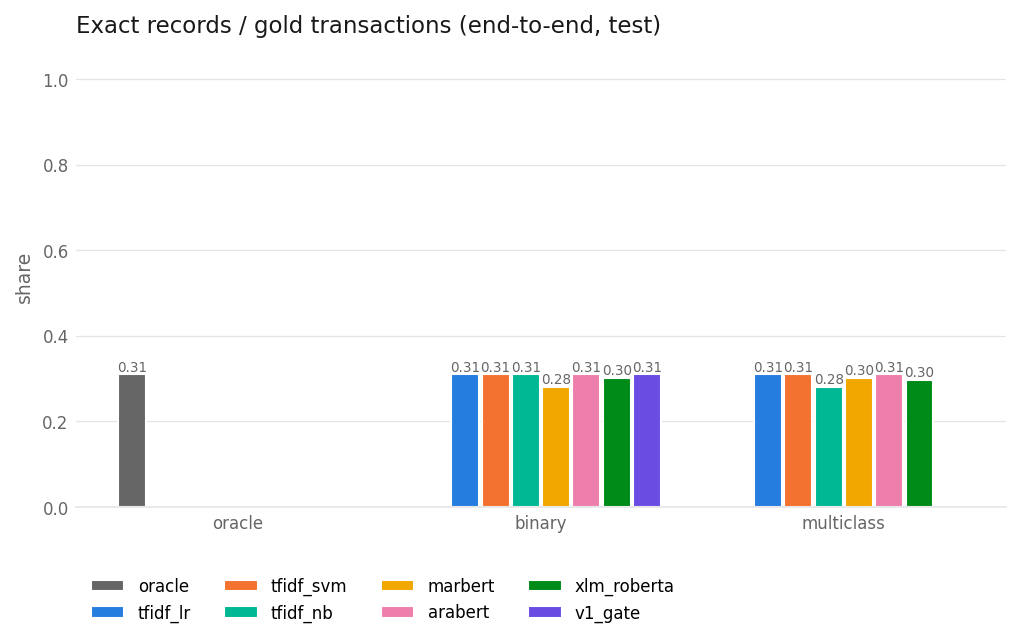

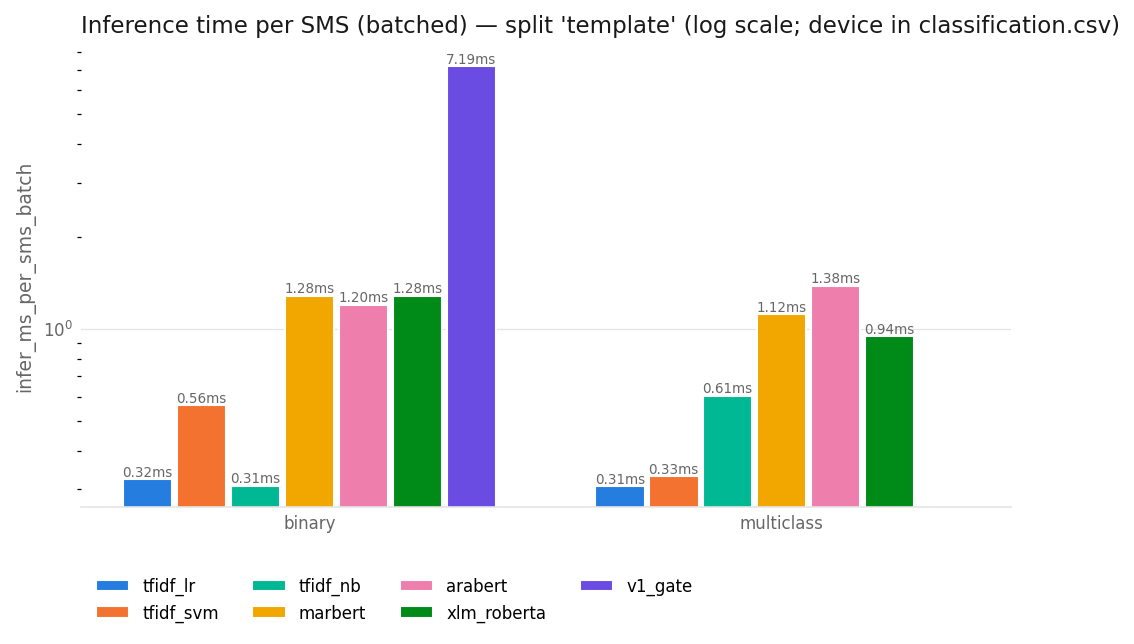

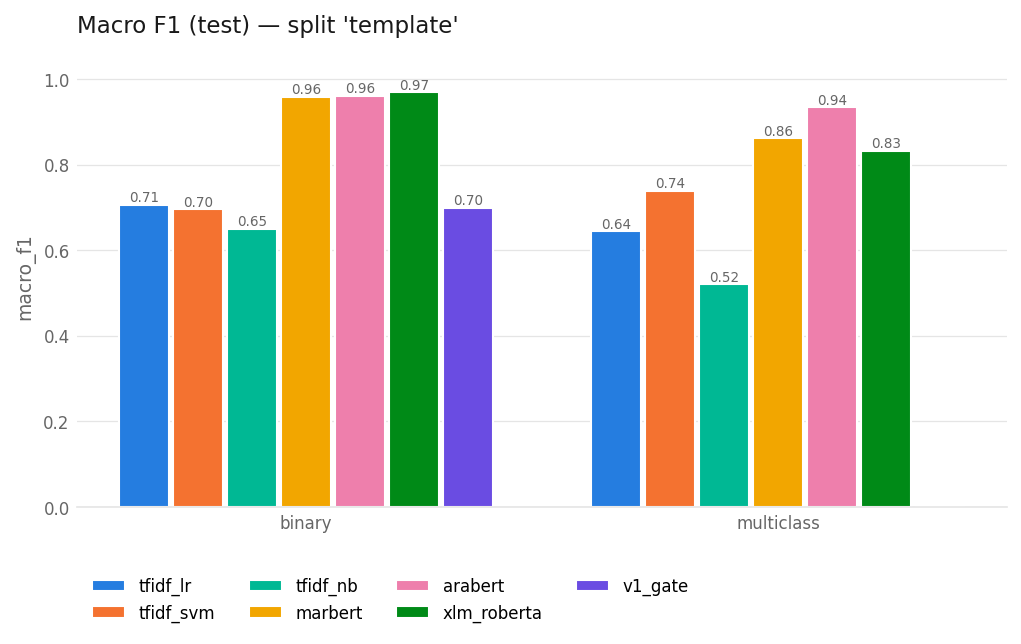

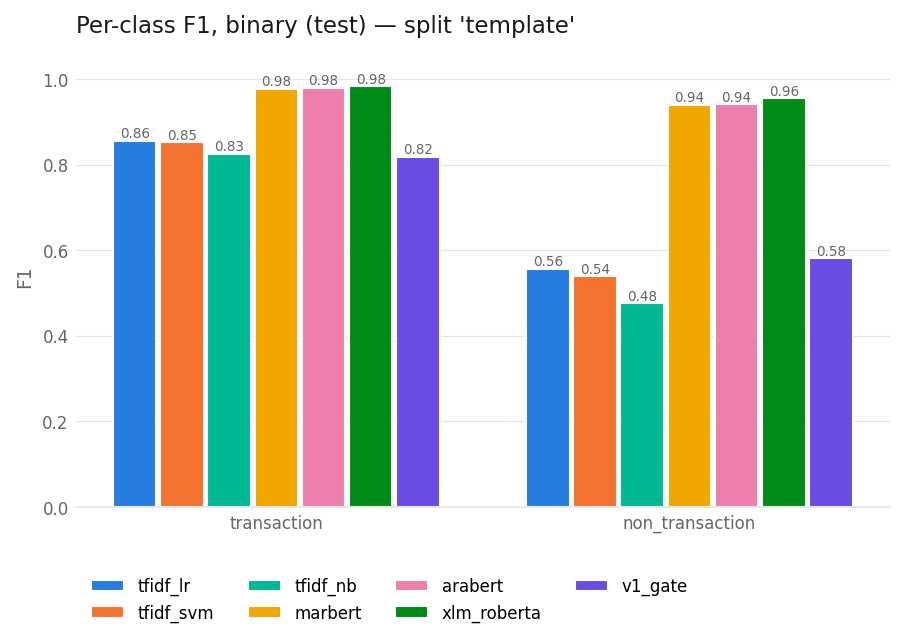

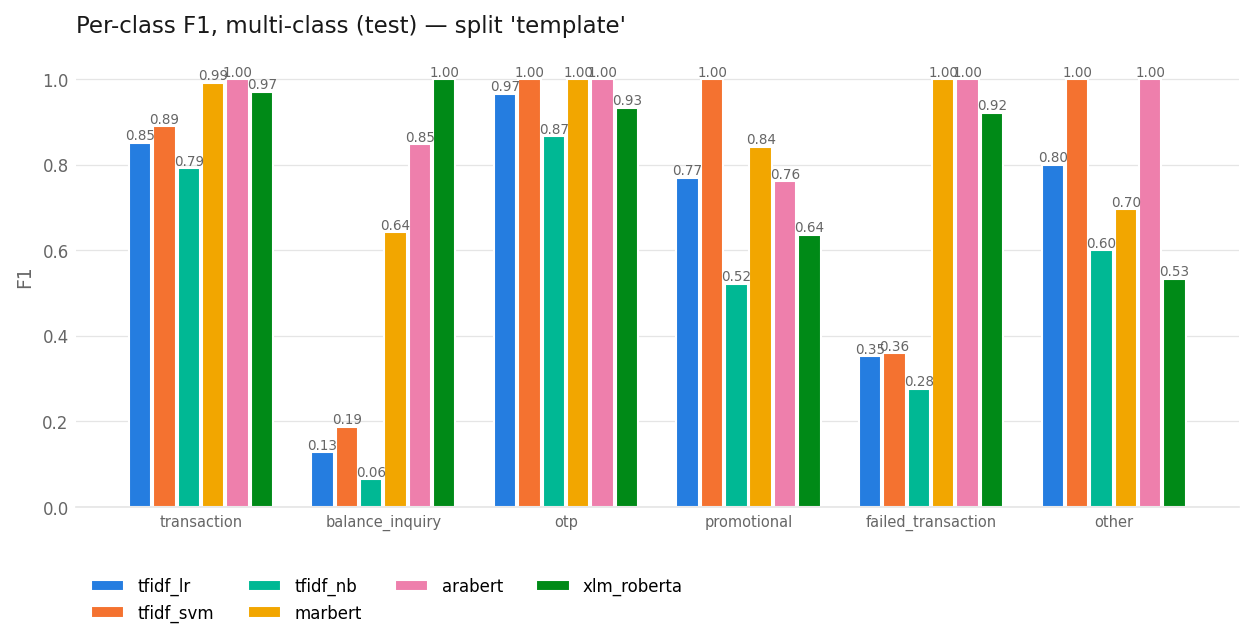

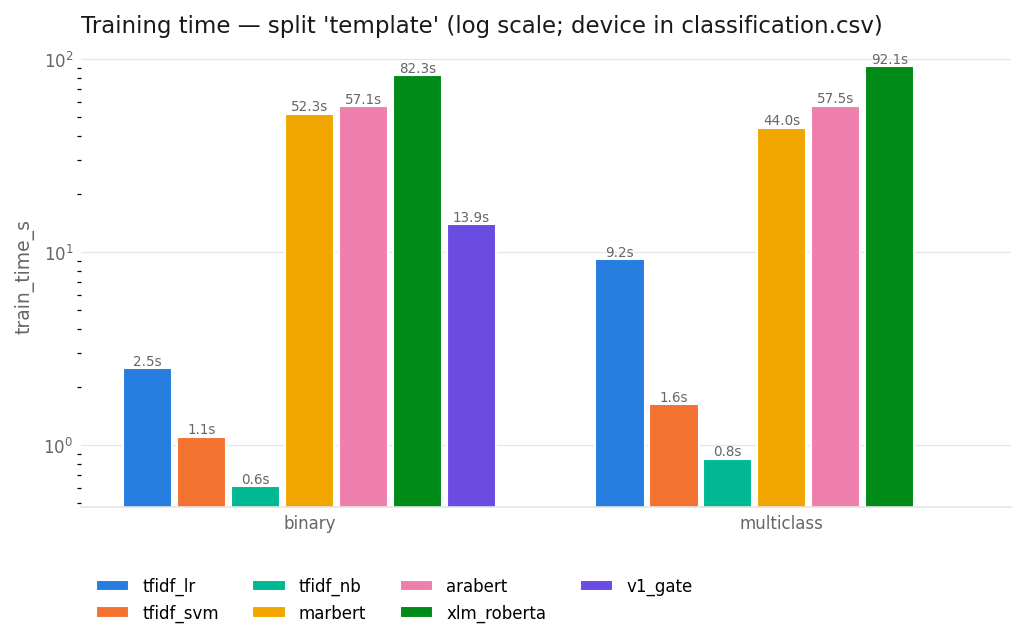

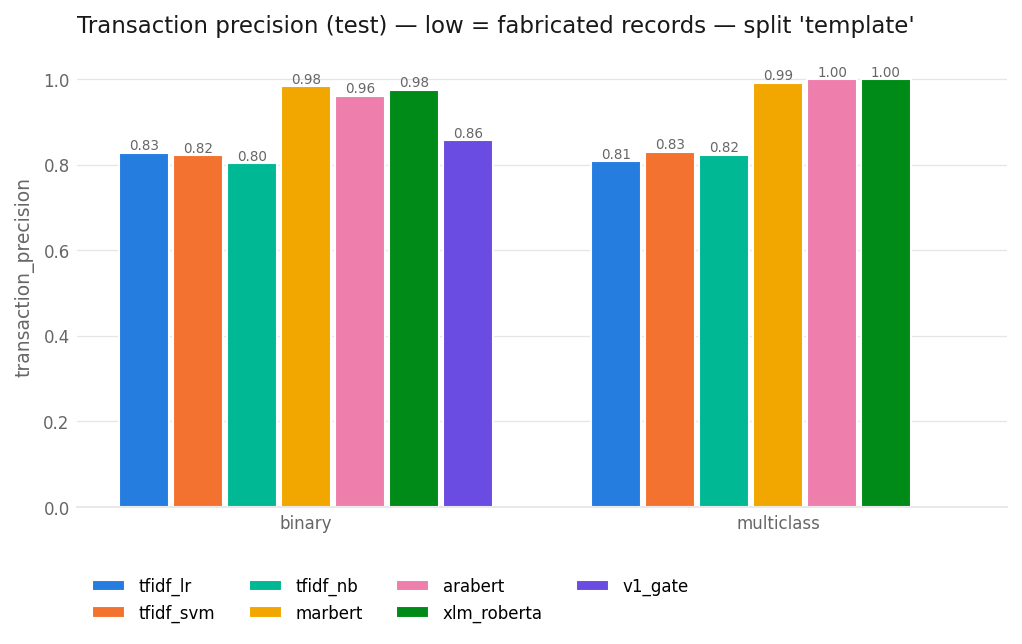

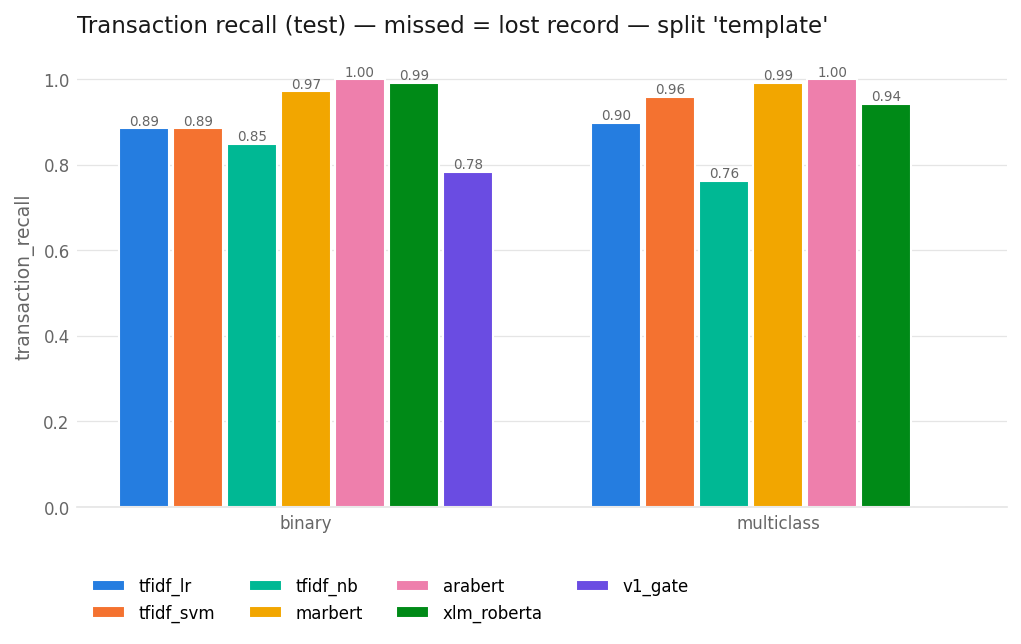

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
bench('compare', '--splits', SPLIT)
from IPython.display import Markdown, Image, display
import glob
for split in [SPLIT]:
    base = os.path.join(os.environ['SMS_V2_OUTPUT'], 'results', split, 'summary')
    display(Markdown(open(os.path.join(base, 'REPORT.md'), encoding='utf-8').read()))
    for png in sorted(glob.glob(os.path.join(base, 'charts', '*.png'))):
        display(Image(png, width=760))

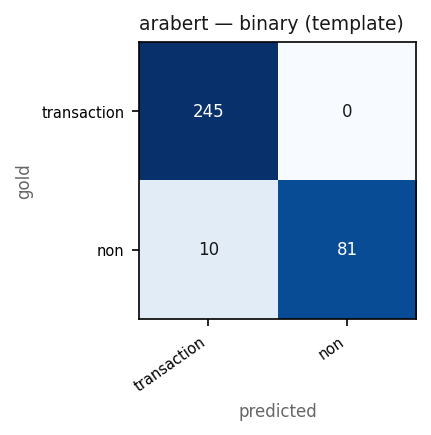

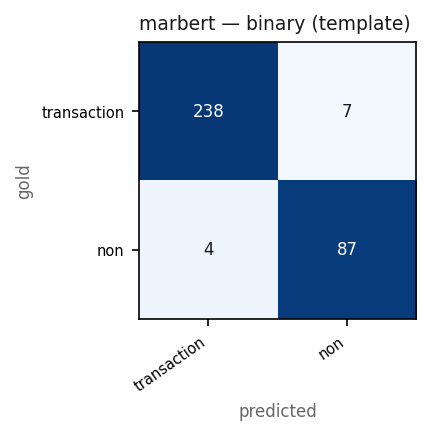

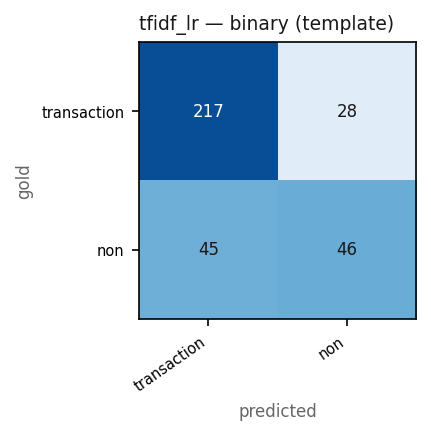

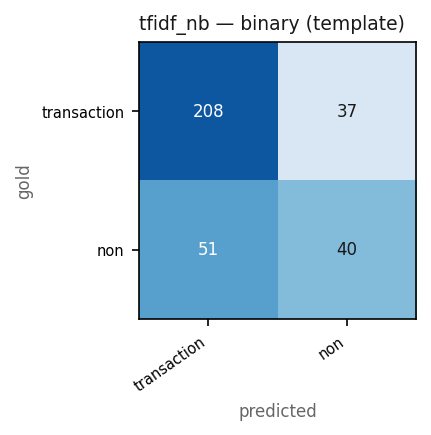

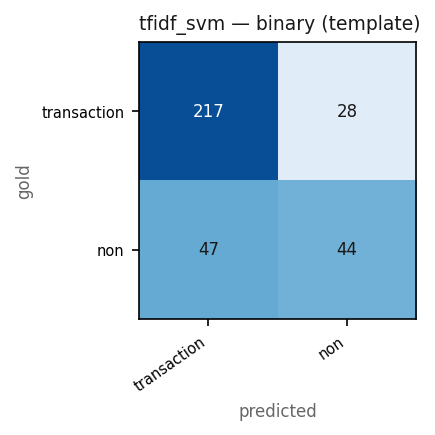

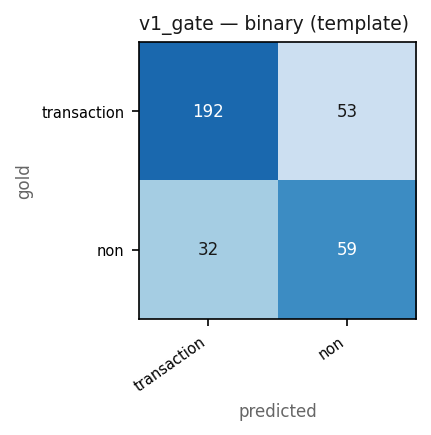

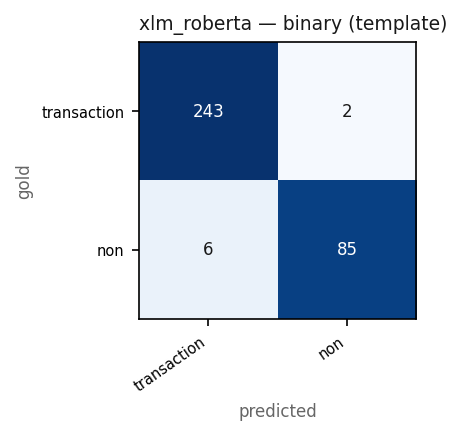

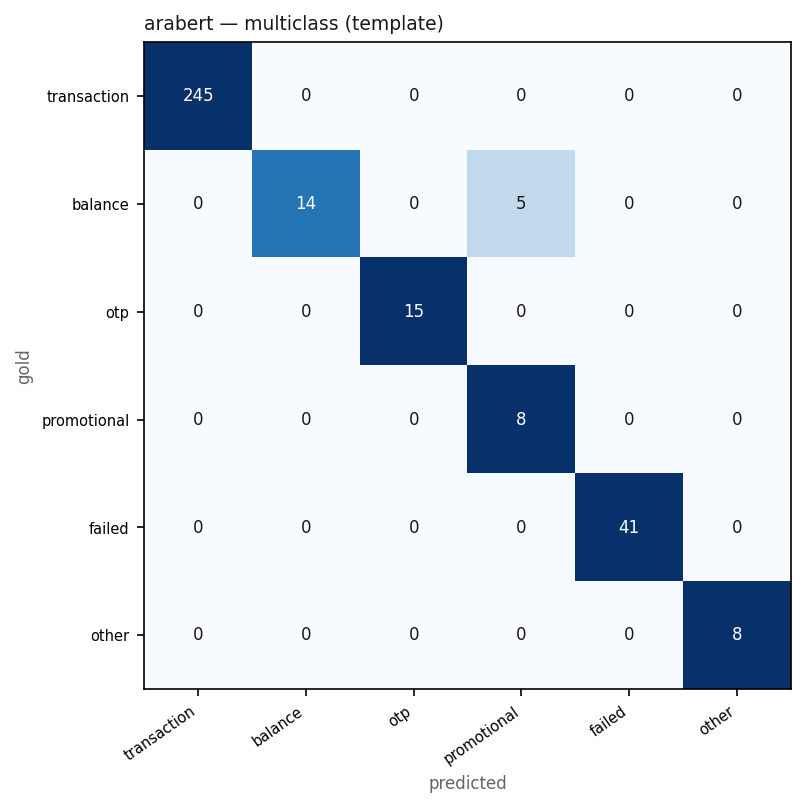

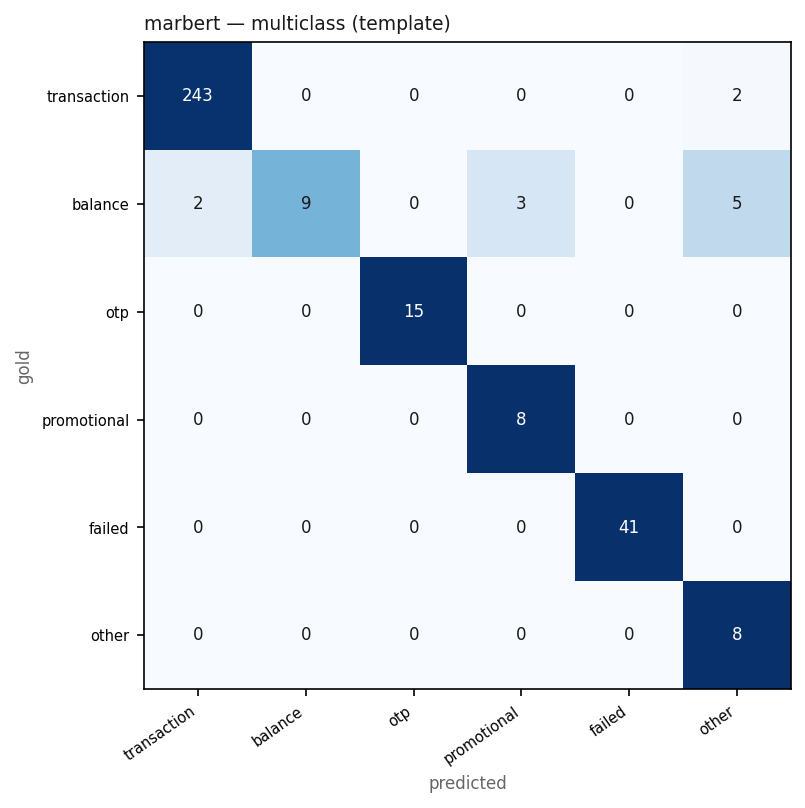

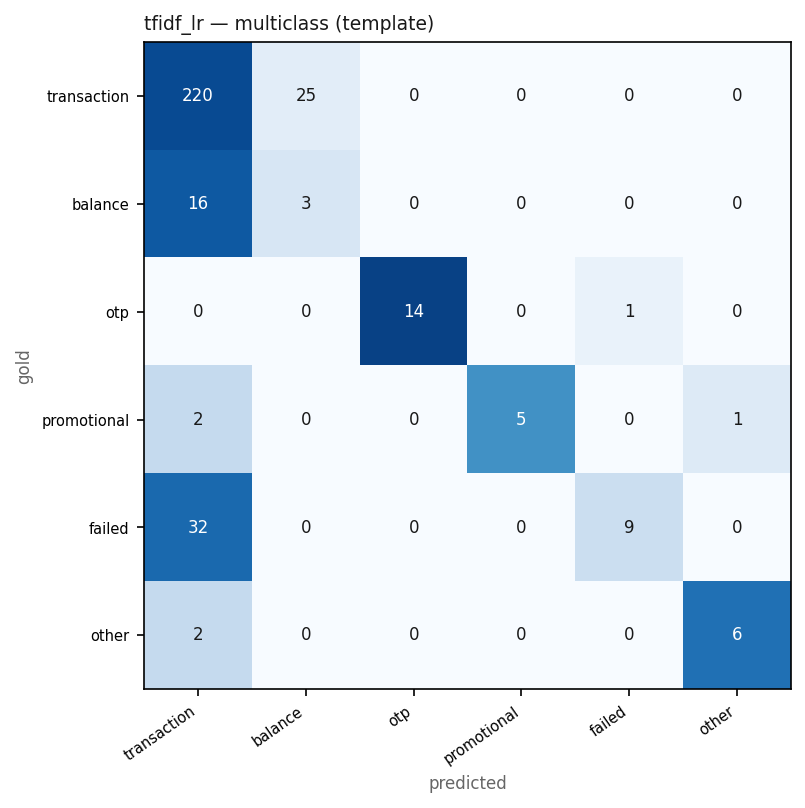

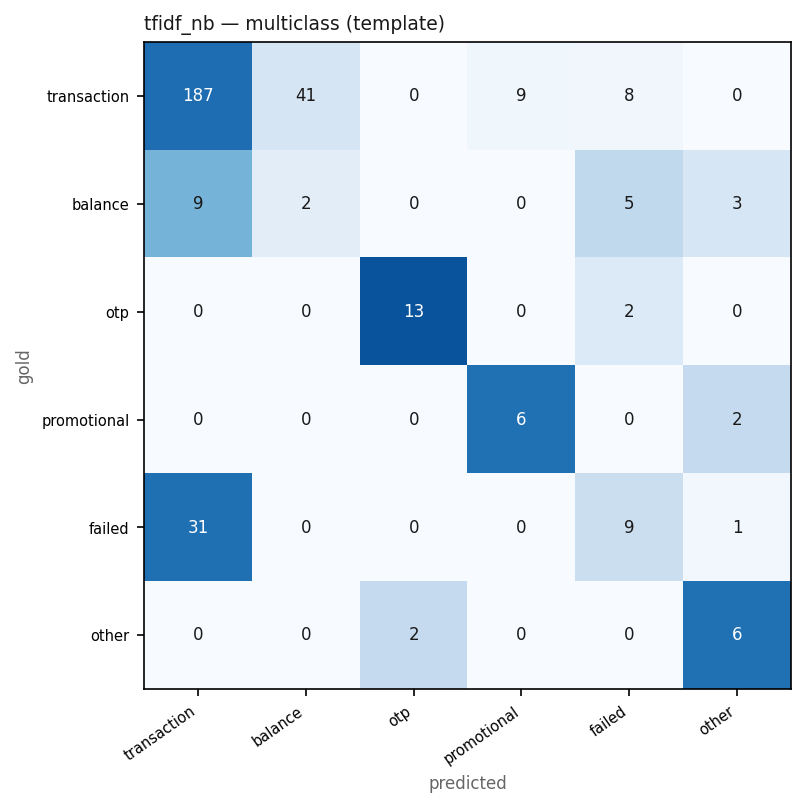

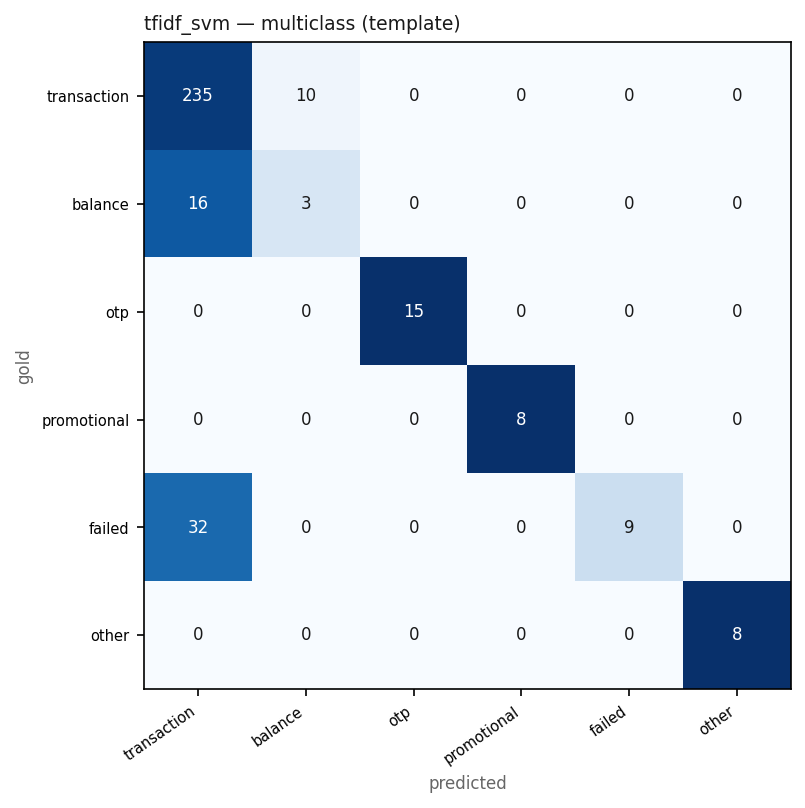

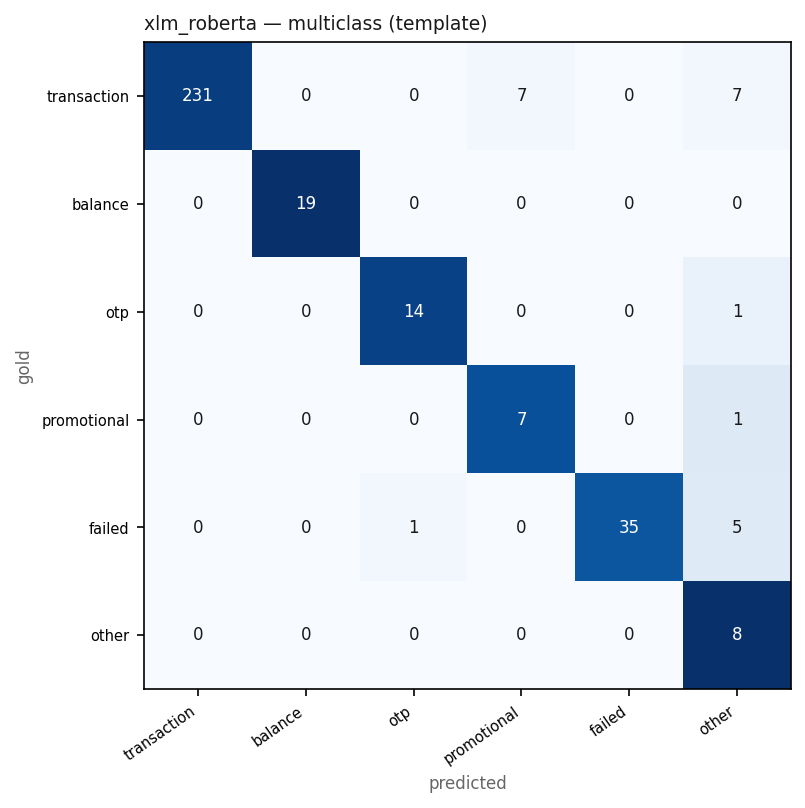

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# confusion matrices
for split in [SPLIT]:
    for png in sorted(glob.glob(os.path.join(os.environ['SMS_V2_OUTPUT'], 'results', split,
                                             'summary', 'confusion_matrices', '*.png'))):
        display(Image(png, width=380))

## 8. Run status and experiment log

Nothing incomplete hides: failed and interrupted runs are listed here.

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
bench('status', '--splits', SPLIT)
log = [json.loads(l) for l in open(os.path.join(os.environ['SMS_V2_OUTPUT'], 'experiment_log.jsonl'), encoding='utf-8')]
bad = [e for e in log if e['event'] in ('failed', 'interrupted')]
print(f'{len(log)} log events, {len(bad)} failed/interrupted')
for e in bad[-10:]:
    print(e['time'], e['event'], e.get('split'), e.get('experiment'), e.get('model'), e.get('error', ''))


split template: {'done': 14, 'FAILED': 0, 'INCOMPLETE': 0, 'not run': 0}
  classify  binary     tfidf_lr     done       
  classify  binary     tfidf_svm    done       
  classify  binary     tfidf_nb     done       
  classify  binary     marbert      done       
  classify  binary     arabert      done       
  classify  binary     xlm_roberta  done       
  classify  binary     v1_gate      done       
  classify  multiclass tfidf_lr     done       
  classify  multiclass tfidf_svm    done       
  classify  multiclass tfidf_nb     done       
  classify  multiclass marbert      done       
  classify  multiclass arabert      done       
  classify  multiclass xlm_roberta  done       
  extract   -          v1_sklearn   done       
108 log events, 0 failed/interrupted


## 9. Use the pipeline

Pick any finished classifier (change the folder name); the extractor stays the same.

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
from sms_pipeline import SmsPipeline
OUT = os.environ['SMS_V2_OUTPUT']
pipe = SmsPipeline.from_dirs(f'{OUT}/models/{SPLIT}/multiclass/tfidf_svm/final',
                             f'{OUT}/models/{SPLIT}/extractor/v1_sklearn')
for sms in ['تم خصم 250.00 جنيه من حسابك ****4321 لدى CARREFOUR MAADI يوم 10/08/2026',
            'Your CIB OTP is 847237. Do not share this code with anyone.',
            'تم رفض المعاملة على بطاقتك المنتهية بـ **4832 بقيمة 191.00 EGP لعدم كفاية الرصيد']:
    print(json.dumps(pipe.process(sms), ensure_ascii=False, indent=1))

{
 "sms": "تم خصم 250.00 جنيه من حسابك ****4321 لدى CARREFOUR MAADI يوم 10/08/2026",
 "stage1": {
  "model": "tfidf_svm",
  "experiment": "multiclass",
  "label": "transaction",
  "score": 0.5937,
  "score_type": "decision_function",
  "routed_to_extraction": true
 },
 "is_transaction": true,
 "record": {
  "amount": 250.0,
  "currency": "EGP",
  "direction": "debit",
  "type": "debit",
  "channel": "card",
  "counterparty": "CARREFOUR MAADI",
  "date": "2026-08-10",
  "datetime": "2026-08-10",
  "account_last4": "4321",
  "fee": null,
  "balance_after": null,
  "reference": null,
  "extraction_ok": true,
  "extraction_note": null
 },
 "reason": null
}
{
 "sms": "Your CIB OTP is 847237. Do not share this code with anyone.",
 "stage1": {
  "model": "tfidf_svm",
  "experiment": "multiclass",
  "label": "otp",
  "score": -0.9491,
  "score_type": "decision_function",
  "routed_to_extraction": false
 },
 "is_transaction": false,
 "record": null,
 "reason": "stage 1: otp"
}
{
 "sms": "تم رفض

---
# Appendix — the original v1 vs v2 (MARBERT extractor) comparison

The cells below are the notebook as it was before the benchmark was added, unchanged. They train the v2
MARBERT **gate + extractor** with `train.py` on `dataset.py`'s four splits and compare against v1 with
`compare.py`. They run in `sms_v2/` and write `runs/` on the Colab disk (not Drive). Their splits are
`dataset.py`'s, **not** the benchmark's, so their numbers are not comparable with sections 4–7.

## 2. Install and check the GPU

Colab ships torch already; only `transformers` is missing.

In [ ]:
!pip install -q transformers
import torch
print('torch', torch.__version__, '| cuda', torch.cuda.is_available(),
      '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU only')
assert torch.cuda.is_available(), 'Runtime -> Change runtime type -> T4 GPU, then re-run'

torch 2.14.1+cu130 | cuda True | Tesla T4


## 3. Sanity checks that need no model

`test_spans.py` asserts the REAL_FORMATS.md failure list; `test_labels.py` prints
v2's extraction ceiling. If either of these is unhappy, training is a waste of time.

In [ ]:
!python dataset.py splits
!python test_spans.py | tail -3
!python test_labels.py | head -14

2200 records, 19 senders, 249 templates

split              train    test   test composition
random              1760     440   19 senders, 284 tx / 156 non-tx
unseen_wording      1803     397   15 senders, 256 tx / 141 non-tx
unseen_sender       1367     833   4 senders, 505 tx / 328 non-tx
real_formats        1000    1200   11 senders, 789 tx / 411 non-tx
  [ok  ] leading dot                    want EUR    v2 EUR

all 19 span tests passed
Oracle round-trip over 1449 transactions
(correct labels in -> what the v2 decoder gets out; this is the ceiling)

  amount            1449/1449   100.0% ############################
  currency          1449/1449   100.0% ############################
  fee               1449/1449   100.0% ############################
  balance_after     1449/1449   100.0% ############################
  merchant          1449/1449   100.0% ############################
  datetime          1447/1449    99.9% ###########################
  account_last4     1449/1449   1

## 4. Smoke test

64 records, 1 epoch. Downloads MARBERT's ~650 MB of weights on the way, so the
first run is slower than the training itself. Fail fast before the real run.

In [ ]:
!python train.py --split random --stage both --limit 64 --epochs 1 --out runs/_smoke
!python predict.py --run runs/_smoke "تم خصم مبلغ 250.00 جنيه من حسابك المنتهي بـ 4321 لدى CARREFOUR" --confidence

split random: 64 train / 440 test
Loading weights: 100% 199/199 [00:00<00:00, 6132.97it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: UBC-NLP/MARBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
-

## 5. Train for real

Four splits × (gate + extractor). On a T4 expect roughly 4–8 min per split at 3
epochs. Drop splits from the list to go faster — `random` and `real_formats` are
the two that matter most (most optimistic and most production-like).

In [ ]:
SPLITS = ['random', 'unseen_wording', 'unseen_sender', 'real_formats']

import subprocess, time
for s in SPLITS:
    t0 = time.time()
    print(f'\n{"=" * 60}\n=== {s}\n{"=" * 60}', flush=True)
    subprocess.run(['python', 'train.py', '--split', s, '--stage', 'both',
                    '--epochs', '3', '--batch-size', '16'], check=True)
    print(f'--- {s} done in {(time.time() - t0) / 60:.1f} min')


=== random
--- random done in 3.1 min

=== unseen_wording
--- unseen_wording done in 3.0 min

=== unseen_sender
--- unseen_sender done in 2.5 min

=== real_formats
--- real_formats done in 1.7 min


## 6. Compare

Trains v1 on the same rows, scores both with v1's own `score()`, writes the report.

In [ ]:
# SPLITS comes from the training cell; this default lets you run compare on its own.
try:
    SPLITS
except NameError:
    SPLITS = ['random', 'unseen_wording', 'unseen_sender', 'real_formats']
splits_arg = ','.join(SPLITS)

!python compare.py --splits $splits_arg

v1 (sms_eval_final, TF-IDF + 4x logistic regression)  vs  v2 (sms_v2, MARBERT gate + MARBERT multi-task extractor)
same train/test rows per split, both graded by evaluate.py:score()


### split random: 1760 train / 440 test
v1 trained + scored in 19.1s
Loading weights: 100% 201/201 [00:00<00:00, 783.31it/s]
Loading weights: 100% 199/199 [00:00<00:00, 26015.04it/s]
[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.

In [ ]:
# A compact headline table out of the json
import json
r = json.load(open('compare_results.json', encoding='utf-8'))
keys = ['tx_f1', 'non_tx_rejected', 'full_record_exact', 'merchant', 'datetime',
        'amount', 'account_last4', 'type']
for split, d in r.items():
    print(f'\n{split}  (n={d["n_test"]})')
    print(f'  {"metric":20s} {"v1":>8s} {"v2":>8s} {"delta":>8s}')
    for k in keys:
        a, b = d['v1'].get(k), (d['v2'] or {}).get(k)
        if a is None or b is None:
            continue
        print(f'  {k:20s} {a:8.3f} {b:8.3f} {b - a:+8.3f}')


random  (n=440)
  metric                     v1       v2    delta
  tx_f1                   1.000    0.996   -0.004
  non_tx_rejected         1.000    0.994   -0.006
  full_record_exact       0.775    0.697   -0.077
  merchant                0.901    0.901   -0.000
  datetime                0.933    0.993   +0.060
  amount                  0.979    0.996   +0.018
  account_last4           0.986    0.908   -0.078
  type                    0.986    0.979   -0.007

unseen_wording  (n=397)
  metric                     v1       v2    delta
  tx_f1                   0.911    0.941   +0.030
  non_tx_rejected         0.652    0.780   +0.128
  full_record_exact       0.488    0.309   -0.180
  merchant                0.741    0.773   +0.031
  datetime                0.980    0.961   -0.020
  amount                  0.949    0.984   +0.035
  account_last4           0.996    0.867   -0.129
  type                    0.851    0.875   +0.024

unseen_sender  (n=833)
  metric                     v1   

## 7. Bring the results home

The report is small. The checkpoints are ~650 MB per stage per split, so only take
them if you intend to serve the model — otherwise keep the report and retrain when
you need to.

In [ ]:
from google.colab import files
files.download('compare_report.txt')
files.download('compare_results.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Optional: the checkpoints, one split at a time (big)
# !tar -czf runs_random.tgz runs/random && ls -lh runs_random.tgz
# files.download('runs_random.tgz')

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
bench('compare', '--splits', SPLIT)
from IPython.display import Markdown, Image, display
import glob
for split in [SPLIT]:
    base = os.path.join(os.environ['SMS_V2_OUTPUT'], 'results', split, 'summary')
    display(Markdown(open(os.path.join(base, 'REPORT.md'), encoding='utf-8').read()))
    for png in sorted(glob.glob(os.path.join(base, 'charts', '*.png'))):
        display(Image(png, width=760))

  ax.legend(frameon=False, fontsize=8, ncol=min(n, 4), loc="upper left",
Traceback (most recent call last):
  File "/content/work/sms_v2/bench.py", line 288, in <module>
    main()
    ~~~~^^
  File "/content/work/sms_v2/bench.py", line 284, in main
    a.fn(a)
    ~~~~^^^
  File "/content/work/sms_v2/bench.py", line 110, in cmd_compare
    compare_models.run(split, make_charts=not a.no_charts)
    ~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/work/sms_v2/evaluation/compare_models.py", line 367, in run
    made = charts(split, rows, per_class, e2e, out) if make_charts else []
           ~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/work/sms_v2/evaluation/compare_models.py", line 243, in charts
    _grouped(ax, S.EXPERIMENTS, models, vals, ylim=(0, 1.08))
    ~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/work/sms_v2/evaluation/compare_models.py", line 213, in _grouped
    ax.legend(frameon=False, fontsize=8, ncol=min(n, 

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/masroofy_sms_v2/outputs/results/template/summary/REPORT.md'

In [ ]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
# confusion matrices
for split in [SPLIT]:
    for png in sorted(glob.glob(os.path.join(os.environ['SMS_V2_OUTPUT'], 'results', split,
                                             'summary', 'confusion_matrices', '*.png'))):
        display(Image(png, width=380))

## 8. Run status and experiment log

Nothing incomplete hides: failed and interrupted runs are listed here.

In [4]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
bench('status', '--splits', SPLIT)
log = [json.loads(l) for l in open(os.path.join(os.environ['SMS_V2_OUTPUT'], 'experiment_log.jsonl'), encoding='utf-8')]
bad = [e for e in log if e['event'] in ('failed', 'interrupted')]
print(f'{len(log)} log events, {len(bad)} failed/interrupted')
for e in bad[-10:]:
    print(e['time'], e['event'], e.get('split'), e.get('experiment'), e.get('model'), e.get('error', ''))


split template: {'done': 14, 'FAILED': 0, 'INCOMPLETE': 0, 'not run': 0}
  classify  binary     tfidf_lr     done       
  classify  binary     tfidf_svm    done       
  classify  binary     tfidf_nb     done       
  classify  binary     marbert      done       
  classify  binary     arabert      done       
  classify  binary     xlm_roberta  done       
  classify  binary     v1_gate      done       
  classify  multiclass tfidf_lr     done       
  classify  multiclass tfidf_svm    done       
  classify  multiclass tfidf_nb     done       
  classify  multiclass marbert      done       
  classify  multiclass arabert      done       
  classify  multiclass xlm_roberta  done       
  extract   -          v1_sklearn   done       
108 log events, 0 failed/interrupted


## 9. Use the pipeline

Pick any finished classifier (change the folder name); the extractor stays the same.

In [5]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
from sms_pipeline import SmsPipeline
OUT = os.environ['SMS_V2_OUTPUT']
pipe = SmsPipeline.from_dirs(f'{OUT}/models/{SPLIT}/multiclass/tfidf_svm/final',
                             f'{OUT}/models/{SPLIT}/extractor/v1_sklearn')
for sms in ['تم خصم 250.00 جنيه من حسابك ****4321 لدى CARREFOUR MAADI يوم 10/08/2026',
            'Your CIB OTP is 847237. Do not share this code with anyone.',
            'تم رفض المعاملة على بطاقتك المنتهية بـ **4832 بقيمة 191.00 EGP لعدم كفاية الرصيد']:
    print(json.dumps(pipe.process(sms), ensure_ascii=False, indent=1))

{
 "sms": "تم خصم 250.00 جنيه من حسابك ****4321 لدى CARREFOUR MAADI يوم 10/08/2026",
 "stage1": {
  "model": "tfidf_svm",
  "experiment": "multiclass",
  "label": "transaction",
  "score": 0.5937,
  "score_type": "decision_function",
  "routed_to_extraction": true
 },
 "is_transaction": true,
 "record": {
  "amount": 250.0,
  "currency": "EGP",
  "direction": "debit",
  "type": "debit",
  "channel": "card",
  "counterparty": "CARREFOUR MAADI",
  "date": "2026-08-10",
  "datetime": "2026-08-10",
  "account_last4": "4321",
  "fee": null,
  "balance_after": null,
  "reference": null,
  "extraction_ok": true,
  "extraction_note": null
 },
 "reason": null
}
{
 "sms": "Your CIB OTP is 847237. Do not share this code with anyone.",
 "stage1": {
  "model": "tfidf_svm",
  "experiment": "multiclass",
  "label": "otp",
  "score": -0.9491,
  "score_type": "decision_function",
  "routed_to_extraction": false
 },
 "is_transaction": false,
 "record": null,
 "reason": "stage 1: otp"
}
{
 "sms": "تم رفض

---
# Experiment 1 — classifier × extractor combinations (AraBERT / MARBERT)

Four end-to-end configurations per classification experiment (A binary, B 6-class) = **8 configurations**:

| | AraBERT extractor | MARBERT extractor |
|---|---|---|
| **AraBERT classifier** | AraBERT → AraBERT | AraBERT → MARBERT |
| **MARBERT classifier** | MARBERT → AraBERT | MARBERT → MARBERT |

**Needed first**
* the classifier runs of section 5 (`arabert` / `marbert`, binary and/or 6-class) — reused, never retrained;
* the two **transformer extractors** (section E1.1): they did not exist before. Architecture = `marbert.py`'s
  extractor (encoder + BIO token head + type head + channel head), trained on the gold transactions of the same
  train split, early-stopped on validation. One training per encoder; GPU, ~same cost as one classifier.

Each combination cell is cheap (no training): it scores *routed by this classifier* × *extracted by this
extractor* on the test set, and runs the **real pipeline one SMS at a time** on 50 test messages for latency
(and checks it reproduces the cached result). A missing model is reported with the command that trains it.
Results: `outputs/results/<split>/extractors/`, `.../combos/<experiment>/<classifier>__<extractor>/`.

In [6]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]

# E1.0 What is done so far for the new experiments (reads Drive; trains nothing)
bench('compare-new', '--splits', SPL, '--no-charts')
display(pd.read_csv(os.path.join(os.environ['SMS_V2_OUTPUT'], 'results', SPL, 'summary_new', 'status.csv')))

summary_new -> /content/drive/MyDrive/masroofy_sms_v2/outputs/results/template/summary_new  (4/18 runs done, 0 charts)


,run,state,make_it
0,extractor marbert,MISSING,python bench.py extract-tf --models marbert --...
1,extractor arabert,MISSING,python bench.py extract-tf --models arabert --...
2,classifier binary/arabert (existing),done,NaN
3,combo binary/arabert__arabert,MISSING,python bench.py combos --experiments binary --...
4,combo binary/arabert__marbert,MISSING,python bench.py combos --experiments binary --...
5,classifier binary/marbert (existing),done,NaN
6,combo binary/marbert__arabert,MISSING,python bench.py combos --experiments binary --...
7,combo binary/marbert__marbert,MISSING,python bench.py combos --experiments binary --...
8,joint binary/marbert,MISSING,python bench.py joint --models marbert --exper...
9,joint binary/arabert,MISSING,python bench.py joint --models arabert --exper...


### E1.1 Train the transformer extractors (GPU, one at a time)

In [7]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]
overwrite = False    # True = redo this finished run (its old result is deleted)

# E1.1a MARBERT extractor
override = None      # e.g. {'epochs': 1} for a quick test; None = config/settings.py
bench('extract-tf', '--models', 'marbert', '--splits', SPL, *(['--overwrite'] if overwrite else []),
      *(['--override', json.dumps(override)] if override else []))

=== extractor template / marbert: 985 train / 219 val gold transactions, 336 test messages

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 13839.60it/s]
[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
  sched.step()
  marbert epoch 1/10 st

0

In [8]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]
overwrite = False    # True = redo this finished run (its old result is deleted)

# E1.1b AraBERT extractor
override = None      # e.g. {'epochs': 1} for a quick test; None = config/settings.py
bench('extract-tf', '--models', 'arabert', '--splits', SPL, *(['--overwrite'] if overwrite else []),
      *(['--override', json.dumps(override)] if override else []))

=== extractor template / arabert: 985 train / 219 val gold transactions, 336 test messages

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 15099.16it/s]
[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
  sched.step()
  arabert epoch 1/10 step 20/31 loss 5.9652
  arabert epoch 1/10 step

0

### E1.2 Combinations — Experiment A (binary classifier)

In [9]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]
overwrite = False    # True = redo this finished run (its old result is deleted)

# A: arabert classifier -> arabert extractor
bench('combos', '--experiments', 'binary', '--classifiers', 'arabert', '--extractors', 'arabert', '--splits', SPL,
      *(['--overwrite'] if overwrite else []))

=== combo template / binary / arabert classifier -> arabert extractor

Loading weights: 100%|██████████| 201/201 [00:06<00:00, 30.05it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1776.99it/s]
    macro-F1 0.961  exact-record F1 0.346  missed 2  false records 9  3.86 ms/SMS (batched)  live 38.5 ms/SMS


0

In [10]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]
overwrite = False    # True = redo this finished run (its old result is deleted)

# A: arabert classifier -> marbert extractor
bench('combos', '--experiments', 'binary', '--classifiers', 'arabert', '--extractors', 'marbert', '--splits', SPL,
      *(['--overwrite'] if overwrite else []))

=== combo template / binary / arabert classifier -> marbert extractor

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1516.92it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 692.58it/s]
    macro-F1 0.961  exact-record F1 0.431  missed 3  false records 10  3.31 ms/SMS (batched)  live 37.6 ms/SMS


0

In [11]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]
overwrite = False    # True = redo this finished run (its old result is deleted)

# A: marbert classifier -> arabert extractor
bench('combos', '--experiments', 'binary', '--classifiers', 'marbert', '--extractors', 'arabert', '--splits', SPL,
      *(['--overwrite'] if overwrite else []))

=== combo template / binary / marbert classifier -> arabert extractor

Loading weights: 100%|██████████| 201/201 [00:17<00:00, 11.80it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2537.97it/s]
    macro-F1 0.959  exact-record F1 0.331  missed 9  false records 3  3.81 ms/SMS (batched)  live 27.8 ms/SMS


0

In [12]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]
overwrite = False    # True = redo this finished run (its old result is deleted)

# A: marbert classifier -> marbert extractor
bench('combos', '--experiments', 'binary', '--classifiers', 'marbert', '--extractors', 'marbert', '--splits', SPL,
      *(['--overwrite'] if overwrite else []))

=== combo template / binary / marbert classifier -> marbert extractor

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 829.68it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 913.03it/s]
    macro-F1 0.959  exact-record F1 0.430  missed 10  false records 4  3.28 ms/SMS (batched)  live 27.0 ms/SMS


0

### E1.3 Combinations — Experiment B (6-class classifier)

In [13]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]
overwrite = False    # True = redo this finished run (its old result is deleted)

# B: arabert classifier -> arabert extractor
bench('combos', '--experiments', 'multiclass', '--classifiers', 'arabert', '--extractors', 'arabert', '--splits', SPL,
      *(['--overwrite'] if overwrite else []))

=== combo template / multiclass / arabert classifier -> arabert extractor

Loading weights: 100%|██████████| 201/201 [00:14<00:00, 13.91it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2003.24it/s]
    macro-F1 0.935  exact-record F1 0.352  missed 2  false records 0  3.93 ms/SMS (batched)  live 27.3 ms/SMS


0

In [14]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]
overwrite = False    # True = redo this finished run (its old result is deleted)

# B: arabert classifier -> marbert extractor
bench('combos', '--experiments', 'multiclass', '--classifiers', 'arabert', '--extractors', 'marbert', '--splits', SPL,
      *(['--overwrite'] if overwrite else []))

=== combo template / multiclass / arabert classifier -> marbert extractor

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1089.79it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1705.33it/s]
    macro-F1 0.935  exact-record F1 0.439  missed 3  false records 0  3.41 ms/SMS (batched)  live 26.9 ms/SMS


0

In [15]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]
overwrite = False    # True = redo this finished run (its old result is deleted)

# B: marbert classifier -> arabert extractor
bench('combos', '--experiments', 'multiclass', '--classifiers', 'marbert', '--extractors', 'arabert', '--splits', SPL,
      *(['--overwrite'] if overwrite else []))

=== combo template / multiclass / marbert classifier -> arabert extractor

Loading weights: 100%|██████████| 201/201 [00:13<00:00, 14.48it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1365.41it/s]
    macro-F1 0.862  exact-record F1 0.345  missed 4  false records 1  3.67 ms/SMS (batched)  live 27.2 ms/SMS


0

In [16]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]
overwrite = False    # True = redo this finished run (its old result is deleted)

# B: marbert classifier -> marbert extractor
bench('combos', '--experiments', 'multiclass', '--classifiers', 'marbert', '--extractors', 'marbert', '--splits', SPL,
      *(['--overwrite'] if overwrite else []))

=== combo template / multiclass / marbert classifier -> marbert extractor

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 2571.01it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3430.79it/s]
    macro-F1 0.862  exact-record F1 0.439  missed 5  false records 2  3.14 ms/SMS (batched)  live 28.7 ms/SMS


0

### E1.4 One SMS in, final JSON out (any finished combination)

In [17]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]

from sms_pipeline import SmsPipeline
pipe = SmsPipeline.from_combo(SPL, 'binary', 'arabert', 'marbert')   # experiment, classifier, extractor
for sms in ['تم خصم 250.00 جنيه من حسابك ****4321 لدى CARREFOUR MAADI يوم 10/08/2026',
            'Your CIB OTP is 847237. Do not share this code with anyone.']:
    print(json.dumps(pipe.process(sms), ensure_ascii=False, indent=1))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{
 "sms": "تم خصم 250.00 جنيه من حسابك ****4321 لدى CARREFOUR MAADI يوم 10/08/2026",
 "stage1": {
  "model": "arabert",
  "experiment": "binary",
  "label": "transaction",
  "score": 0.997,
  "score_type": "probability",
  "routed_to_extraction": true
 },
 "is_transaction": true,
 "record": {
  "amount": 250.0,
  "currency": "EGP",
  "direction": "debit",
  "type": "debit",
  "channel": "card",
  "counterparty": "CARREFOUR MAADI",
  "date": "2026-08-10",
  "datetime": "2026-08-10",
  "account_last4": "4321",
  "fee": null,
  "balance_after": null,
  "reference": null,
  "extraction_ok": true,
  "extraction_note": null
 },
 "reason": null
}
{
 "sms": "Your CIB OTP is 847237. Do not share this code with anyone.",
 "stage1": {
  "model": "arabert",
  "experiment": "binary",
  "label": "non_transaction",
  "score": 0.0017,
  "score_type": "probability",
  "routed_to_extraction": false
 },
 "is_transaction": false,
 "record": null,
 "reason": "stage 1: non_transaction"
}


---
# Experiment 2 — one joint model (classification + extraction in one workflow)

The runs above use **two models** (classifier, then extractor). Here **one** AraBERT or MARBERT has a classification
head (binary or 6-class: the same gold labels as section 5, no new classes) **and** the extractor's heads on one
shared encoder, trained together. One forward pass returns the class and the record. Loss = class-weighted CE +
the extraction losses (gold transactions only). Early stopping on mean(val macro-F1, val full-record exact).
New training per cell (GPU). Results: `outputs/results/<split>/joint/<experiment>/<model>/`.

In [18]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]
overwrite = False    # True = redo this finished run (its old result is deleted)

# E2 joint arabert — A: binary class head
override = None      # e.g. {'epochs': 1} for a quick test; None = config/settings.py
bench('joint', '--models', 'arabert', '--experiments', 'binary', '--splits', SPL,
      *(['--overwrite'] if overwrite else []), *(['--override', json.dumps(override)] if override else []))

=== joint template / binary / arabert: 1541 train, 323 val, 336 test (one model: class head + extraction heads)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 814.25it/s]
[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
  sched.step()
  arabert epoch 1/10 step 20/49 loss 6.9749
  arab

0

In [19]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]
overwrite = False    # True = redo this finished run (its old result is deleted)

# E2 joint arabert — B: multiclass class head
override = None      # e.g. {'epochs': 1} for a quick test; None = config/settings.py
bench('joint', '--models', 'arabert', '--experiments', 'multiclass', '--splits', SPL,
      *(['--overwrite'] if overwrite else []), *(['--override', json.dumps(override)] if override else []))

=== joint template / multiclass / arabert: 1541 train, 323 val, 336 test (one model: class head + extraction heads)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 809.96it/s]
[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
  sched.step()
  arabert epoch 1/10 step 20/49 loss 8.2550
  

0

In [20]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]
overwrite = False    # True = redo this finished run (its old result is deleted)

# E2 joint marbert — A: binary class head
override = None      # e.g. {'epochs': 1} for a quick test; None = config/settings.py
bench('joint', '--models', 'marbert', '--experiments', 'binary', '--splits', SPL,
      *(['--overwrite'] if overwrite else []), *(['--override', json.dumps(override)] if override else []))

=== joint template / binary / marbert: 1541 train, 323 val, 336 test (one model: class head + extraction heads)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 25988.31it/s]
[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
  sched.step()
  

0

In [21]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]
overwrite = False    # True = redo this finished run (its old result is deleted)

# E2 joint marbert — B: multiclass class head
override = None      # e.g. {'epochs': 1} for a quick test; None = config/settings.py
bench('joint', '--models', 'marbert', '--experiments', 'multiclass', '--splits', SPL,
      *(['--overwrite'] if overwrite else []), *(['--override', json.dumps(override)] if override else []))

=== joint template / multiclass / marbert: 1541 train, 323 val, 336 test (one model: class head + extraction heads)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 13584.85it/s]
[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
  sched.step(

0

In [22]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]
overwrite = False    # True = redo this finished run (its old result is deleted)

# E2 joint marbert — B: multiclass class head
override = None      # e.g. {'epochs': 1} for a quick test; None = config/settings.py
bench('joint', '--models', 'marbert', '--experiments', 'multiclass', '--splits', SPL,
      *(['--overwrite'] if overwrite else []), *(['--override', json.dumps(override)] if override else []))

skip joint template/multiclass/marbert: already complete (/content/drive/MyDrive/masroofy_sms_v2/outputs/results/template/joint/multiclass/marbert). Pass --overwrite to redo it.


0

In [23]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]

# E2 one SMS in, final JSON out, ONE model
from sms_pipeline import JointPipeline
pipe = JointPipeline.from_run(SPL, 'multiclass', 'arabert')         # experiment, model
for sms in ['تم خصم 250.00 جنيه من حسابك ****4321 لدى CARREFOUR MAADI يوم 10/08/2026',
            'Your CIB OTP is 847237. Do not share this code with anyone.']:
    print(json.dumps(pipe.process(sms), ensure_ascii=False, indent=1))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{
 "sms": "تم خصم 250.00 جنيه من حسابك ****4321 لدى CARREFOUR MAADI يوم 10/08/2026",
 "stage1": {
  "model": "joint_arabert",
  "experiment": "multiclass",
  "label": "transaction",
  "score": 0.9978,
  "score_type": "probability",
  "routed_to_extraction": true,
  "workflow": "joint (one model, one forward pass)"
 },
 "is_transaction": true,
 "record": {
  "amount": 250.0,
  "currency": "EGP",
  "direction": "debit",
  "type": "debit",
  "channel": "card",
  "counterparty": "CARREFOUR MAADI",
  "date": "2026-08-10",
  "datetime": "2026-08-10",
  "account_last4": "4321",
  "fee": null,
  "balance_after": null,
  "reference": null,
  "extraction_ok": true,
  "extraction_note": null
 },
 "reason": null
}
{
 "sms": "Your CIB OTP is 847237. Do not share this code with anyone.",
 "stage1": {
  "model": "joint_arabert",
  "experiment": "multiclass",
  "label": "otp",
  "score": 0.0001,
  "score_type": "probability",
  "routed_to_extraction": false,
  "workflow": "joint (one model, one forwar

### E3. Comparison: Experiment 1 vs Experiment 2 vs the existing two-stage runs

Writes `outputs/results/<split>/summary_new/` (tables, `REPORT_NEW.md`, charts, confusion matrices). The existing
`summary/` is not touched. Re-run any time; it only reads finished runs.

summary_new -> /content/drive/MyDrive/masroofy_sms_v2/outputs/results/template/summary_new  (18/18 runs done, 18 charts)


# New experiments — split `template`

Exp 1 = four classifier → extractor combinations (two separate models, run automatically one after the other). Exp 2 = one joint model (one forward pass gives the class and the record). `ref` rows = the existing classifier with the v1 extractor. All numbers are on the same fixed test set; field accuracy is over ALL gold transactions with misses scored wrong.

## Status

| run | state | make_it |
|---|---|---|
| extractor marbert | done |  |
| extractor arabert | done |  |
| classifier binary/arabert (existing) | done |  |
| combo binary/arabert__arabert | done |  |
| combo binary/arabert__marbert | done |  |
| classifier binary/marbert (existing) | done |  |
| combo binary/marbert__arabert | done |  |
| combo binary/marbert__marbert | done |  |
| joint binary/marbert | done |  |
| joint binary/arabert | done |  |
| classifier multiclass/arabert (existing) | done |  |
| combo multiclass/arabert__arabert | done |  |
| combo multiclass/arabert__marbert | done |  |
| classifier multiclass/marbert (existing) | done |  |
| combo multiclass/marbert__arabert | done |  |
| combo multiclass/marbert__marbert | done |  |
| joint multiclass/marbert | done |  |
| joint multiclass/arabert | done |  |

## Standalone extraction (perfect Stage 1, gold test transactions)

| extractor | n | amount_acc | currency_acc | counterparty_f1 | date_acc | direction_acc | type_acc | account_last4_acc | full_record_exact | ms_per_sms |
|---|---|---|---|---|---|---|---|---|---|---|
| v1_sklearn | 245 | 0.967 | 0.984 | 0.655 | 0.820 | 0.804 | 0.600 | 0.943 | 0.310 | 10.327 |
| marbert | 245 | 0.988 | 0.992 | 0.858 | 0.988 | 0.735 | 0.633 | 0.943 | 0.437 | 2.780 |
| arabert | 245 | 0.992 | 0.980 | 0.807 | 0.996 | 0.743 | 0.498 | 0.963 | 0.351 | 3.502 |

## Classification (the routing decision of each workflow)

| experiment | workflow | accuracy | macro_precision | macro_recall | macro_f1 | transaction_precision | transaction_recall |
|---|---|---|---|---|---|---|---|
| binary | arabert classifier (Exp 1, shared by its 2 combos) | 0.970 | 0.980 | 0.945 | 0.961 | 0.961 | 1.000 |
| binary | marbert classifier (Exp 1, shared by its 2 combos) | 0.967 | 0.955 | 0.964 | 0.959 | 0.983 | 0.971 |
| binary | joint marbert (one model) | 0.991 | 0.994 | 0.984 | 0.989 | 0.988 | 1.000 |
| binary | joint arabert (one model) | 0.973 | 0.982 | 0.951 | 0.965 | 0.965 | 1.000 |
| multiclass | arabert classifier (Exp 1, shared by its 2 combos) | 0.985 | 0.936 | 0.956 | 0.935 | 1.000 | 1.000 |
| multiclass | marbert classifier (Exp 1, shared by its 2 combos) | 0.964 | 0.875 | 0.911 | 0.862 | 0.992 | 0.992 |
| multiclass | joint marbert (one model) | 1.000 | 1.000 | 1.000 | 1.000 | 1.000 | 1.000 |
| multiclass | joint arabert (one model) | 0.899 | 0.980 | 0.829 | 0.870 | 0.878 | 1.000 |

## End to end

| experiment | kind | workflow | e2e_exact_precision | e2e_exact_recall | e2e_exact_f1 | missed_transactions | false_records | amount_acc | currency_acc | counterparty_acc | date_acc | direction_acc | type_acc | account_last4_acc |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| binary | combo | arabert clf → arabert ext | 0.341 | 0.351 | 0.346 | 2 | 9 | 0.992 | 0.980 | 0.837 | 0.996 | 0.743 | 0.498 | 0.963 |
| binary | combo | arabert clf → marbert ext | 0.425 | 0.437 | 0.431 | 3 | 10 | 0.988 | 0.992 | 0.861 | 0.988 | 0.735 | 0.633 | 0.943 |
| binary | combo | marbert clf → arabert ext | 0.335 | 0.327 | 0.331 | 9 | 3 | 0.963 | 0.951 | 0.812 | 0.967 | 0.714 | 0.469 | 0.963 |
| binary | combo | marbert clf → marbert ext | 0.435 | 0.424 | 0.430 | 10 | 4 | 0.959 | 0.963 | 0.849 | 0.959 | 0.706 | 0.604 | 0.943 |
| binary | ref | arabert clf → v1 ext (existing) | 0.298 | 0.310 | 0.304 | 0 | 10 | 0.967 | 0.984 | 0.633 | 0.820 | 0.804 | 0.600 | 0.943 |
| binary | ref | marbert clf → v1 ext (existing) | 0.285 | 0.282 | 0.283 | 7 | 4 | 0.939 | 0.955 | 0.604 | 0.792 | 0.776 | 0.571 | 0.943 |
| binary | joint | joint marbert (one model) | 0.496 | 0.502 | 0.499 | 0 | 3 | 1.000 | 1.000 | 0.898 | 1.000 | 0.837 | 0.657 | 0.927 |
| binary | joint | joint arabert (one model) | 0.392 | 0.392 | 0.392 | 1 | 1 | 0.996 | 0.971 | 0.857 | 0.996 | 0.669 | 0.514 | 0.980 |
| multiclass | combo | arabert clf → arabert ext | 0.354 | 0.351 | 0.352 | 2 | 0 | 0.992 | 0.980 | 0.837 | 0.996 | 0.743 | 0.498 | 0.963 |
| multiclass | combo | arabert clf → marbert ext | 0.442 | 0.437 | 0.439 | 3 | 0 | 0.988 | 0.992 | 0.861 | 0.988 | 0.735 | 0.633 | 0.943 |
| multiclass | combo | marbert clf → arabert ext | 0.347 | 0.343 | 0.345 | 4 | 1 | 0.984 | 0.971 | 0.829 | 0.988 | 0.735 | 0.490 | 0.963 |
| multiclass | combo | marbert clf → marbert ext | 0.442 | 0.437 | 0.439 | 5 | 2 | 0.980 | 0.984 | 0.861 | 0.980 | 0.727 | 0.624 | 0.943 |
| multiclass | ref | arabert clf → v1 ext (existing) | 0.310 | 0.310 | 0.310 | 0 | 0 | 0.967 | 0.984 | 0.633 | 0.820 | 0.804 | 0.600 | 0.943 |
| multiclass | ref | marbert clf → v1 ext (existing) | 0.302 | 0.302 | 0.302 | 2 | 2 | 0.959 | 0.976 | 0.624 | 0.812 | 0.796 | 0.592 | 0.943 |
| multiclass | joint | joint marbert (one model) | 0.543 | 0.543 | 0.543 | 0 | 0 | 1.000 | 1.000 | 0.873 | 1.000 | 0.776 | 0.722 | 0.943 |
| multiclass | joint | joint arabert (one model) | 0.319 | 0.355 | 0.336 | 0 | 28 | 0.992 | 0.971 | 0.878 | 1.000 | 0.751 | 0.535 | 0.988 |

## Time per SMS (ms)

Batched = whole test set at once; live = one SMS at a time through the real pipeline (median). Pipeline (batched) = classification + share routed × extraction.


| experiment | workflow | classification_ms | extraction_ms | pipeline_ms | live_classification_ms | live_extraction_ms | live_pipeline_ms | live_agreement |
|---|---|---|---|---|---|---|---|---|
| binary | arabert clf → arabert ext | 1.198 | 3.502 | 3.856 | 19.239 | 16.338 | 38.468 | 1.000 |
| binary | arabert clf → marbert ext | 1.198 | 2.780 | 3.307 | 18.937 | 22.169 | 37.581 | 1.000 |
| binary | marbert clf → arabert ext | 1.283 | 3.502 | 3.806 | 13.979 | 15.514 | 27.837 | 1.000 |
| binary | marbert clf → marbert ext | 1.283 | 2.780 | 3.285 | 17.706 | 18.764 | 27.002 | 1.000 |
| binary | arabert clf → v1 ext (existing) | 1.198 | 10.327 | 9.035 |  |  |  |  |
| binary | marbert clf → v1 ext (existing) | 1.283 | 10.327 | 8.721 |  |  |  |  |
| binary | joint marbert (one model) |  |  | 1.752 |  |  | 21.701 |  |
| binary | joint arabert (one model) |  |  | 2.131 |  |  | 15.175 |  |
| multiclass | arabert clf → arabert ext | 1.381 | 3.502 | 3.935 | 16.948 | 18.321 | 27.252 | 1.000 |
| multiclass | arabert clf → marbert ext | 1.381 | 2.780 | 3.408 | 13.454 | 14.439 | 26.938 | 1.000 |
| multiclass | marbert clf → arabert ext | 1.116 | 3.502 | 3.670 | 14.652 | 15.845 | 27.188 | 1.000 |
| multiclass | marbert clf → marbert ext | 1.116 | 2.780 | 3.143 | 13.973 | 15.184 | 28.722 | 1.000 |
| multiclass | arabert clf → v1 ext (existing) | 1.381 | 10.327 | 8.911 |  |  |  |  |
| multiclass | marbert clf → v1 ext (existing) | 1.116 | 10.327 | 8.646 |  |  |  |  |
| multiclass | joint marbert (one model) |  |  | 1.635 |  |  | 14.851 |  |
| multiclass | joint arabert (one model) |  |  | 2.114 |  |  | 17.165 |  |


Charts: charts/e2e_exact_f1.png, charts/e2e_exact_precision.png, charts/e2e_exact_recall.png, charts/macro_f1.png, charts/missed_transactions.png, charts/false_records.png, charts/field_accuracy_binary.png, charts/field_accuracy_multiclass.png, charts/latency_binary.png, charts/latency_multiclass.png, confusion_matrices/binary_arabert_classifier.png, confusion_matrices/binary_marbert_classifier.png, confusion_matrices/binary_joint_marbert.png, confusion_matrices/binary_joint_arabert.png, confusion_matrices/multiclass_arabert_classifier.png, confusion_matrices/multiclass_marbert_classifier.png, confusion_matrices/multiclass_joint_marbert.png, confusion_matrices/multiclass_joint_arabert.png


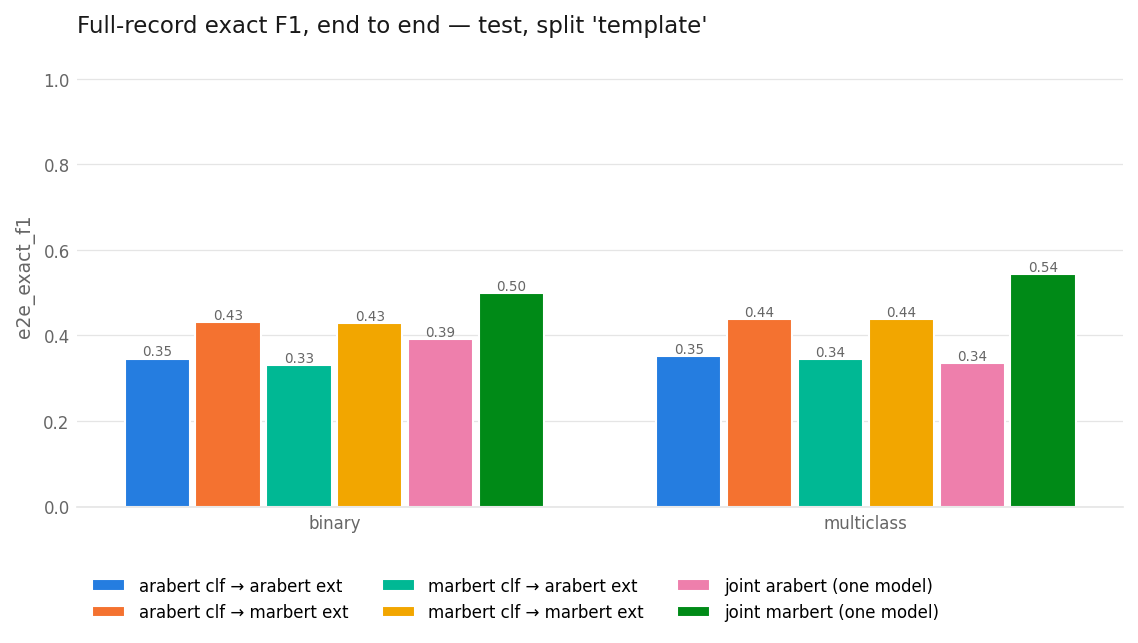

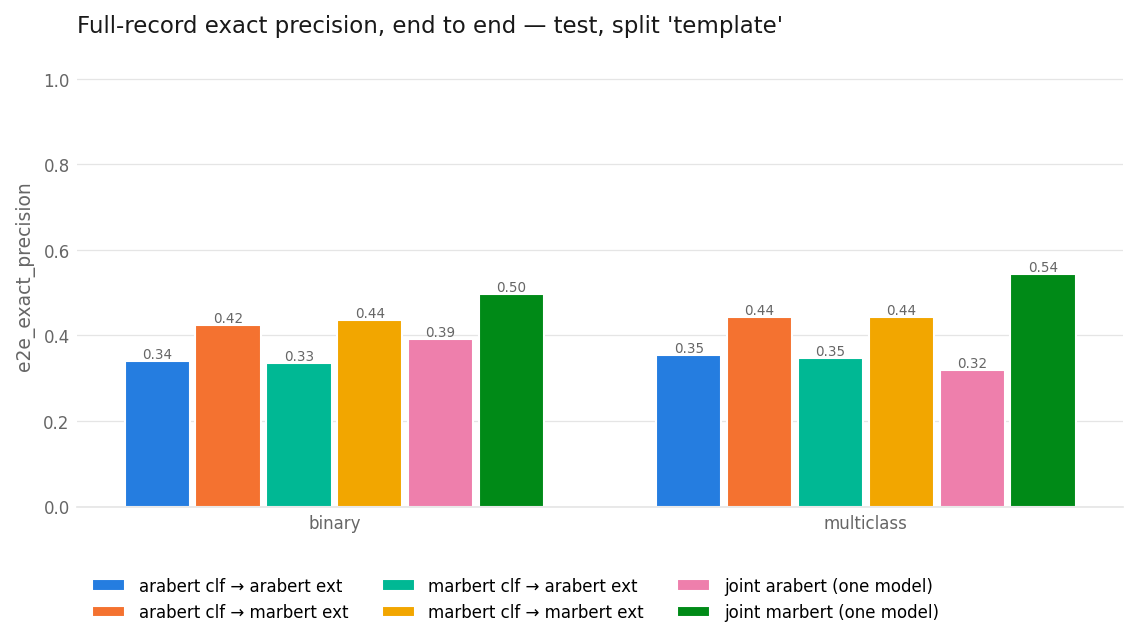

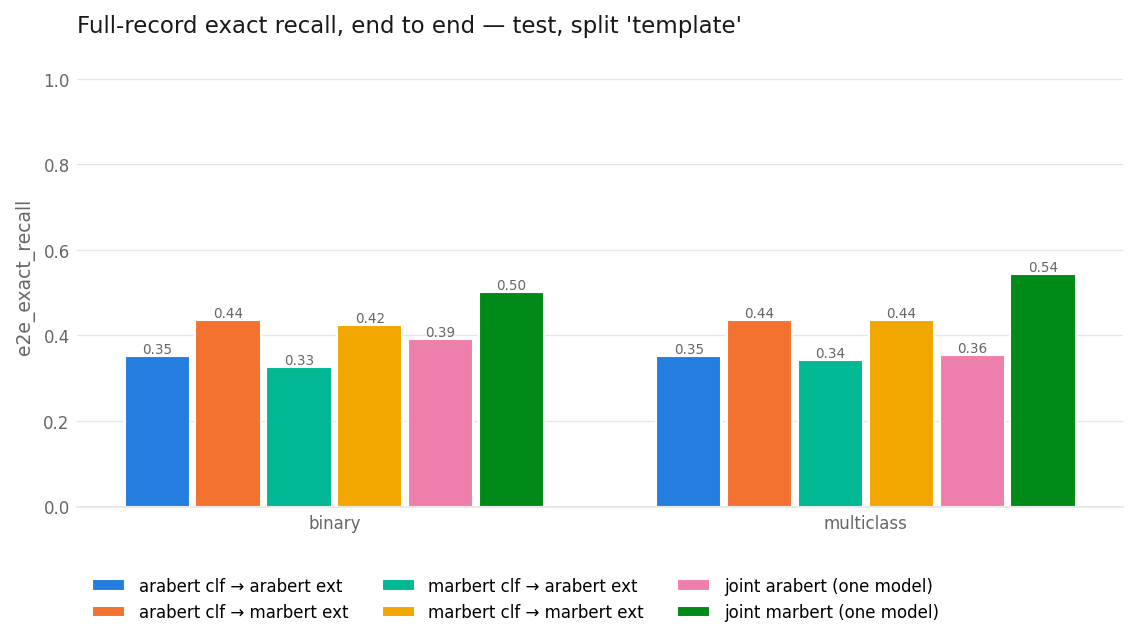

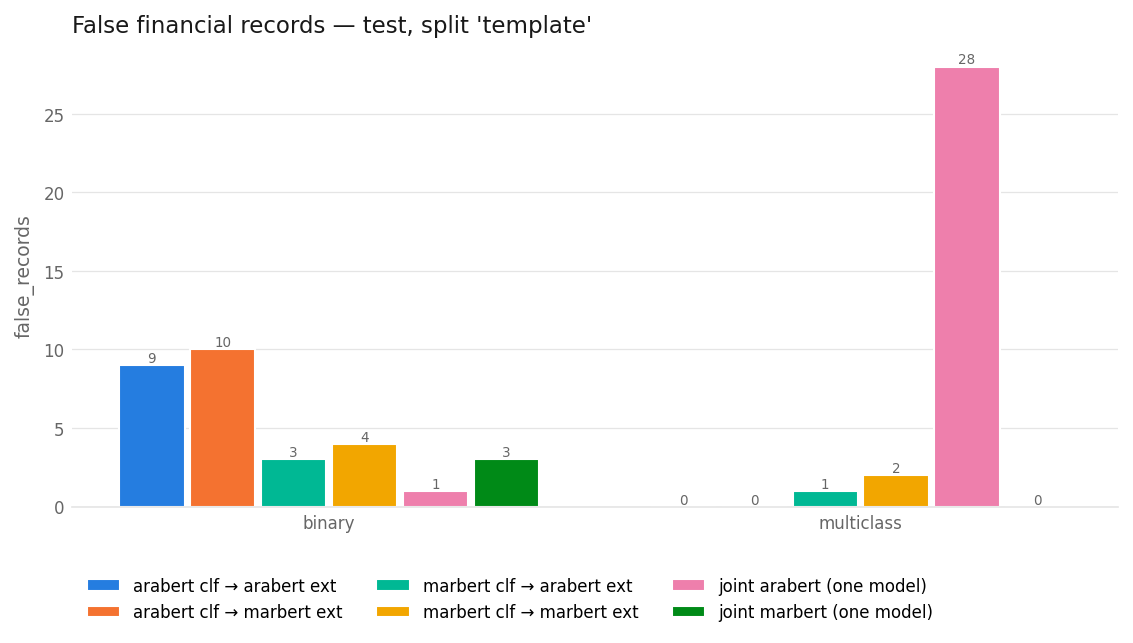

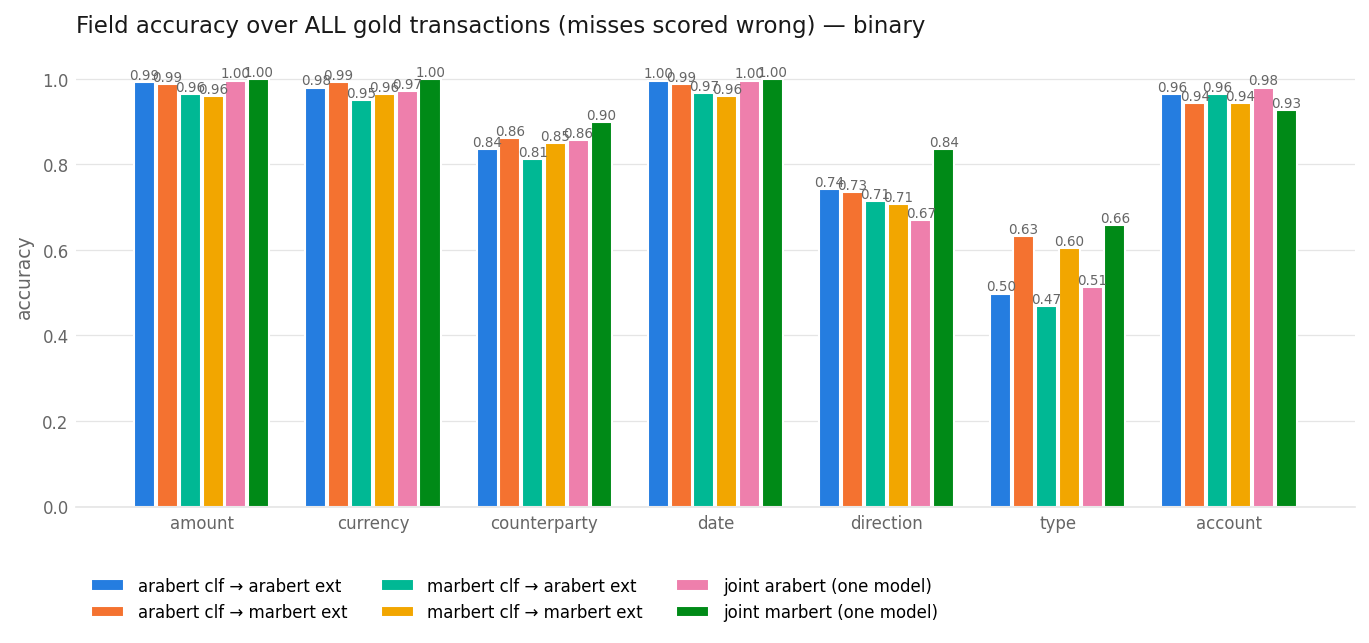

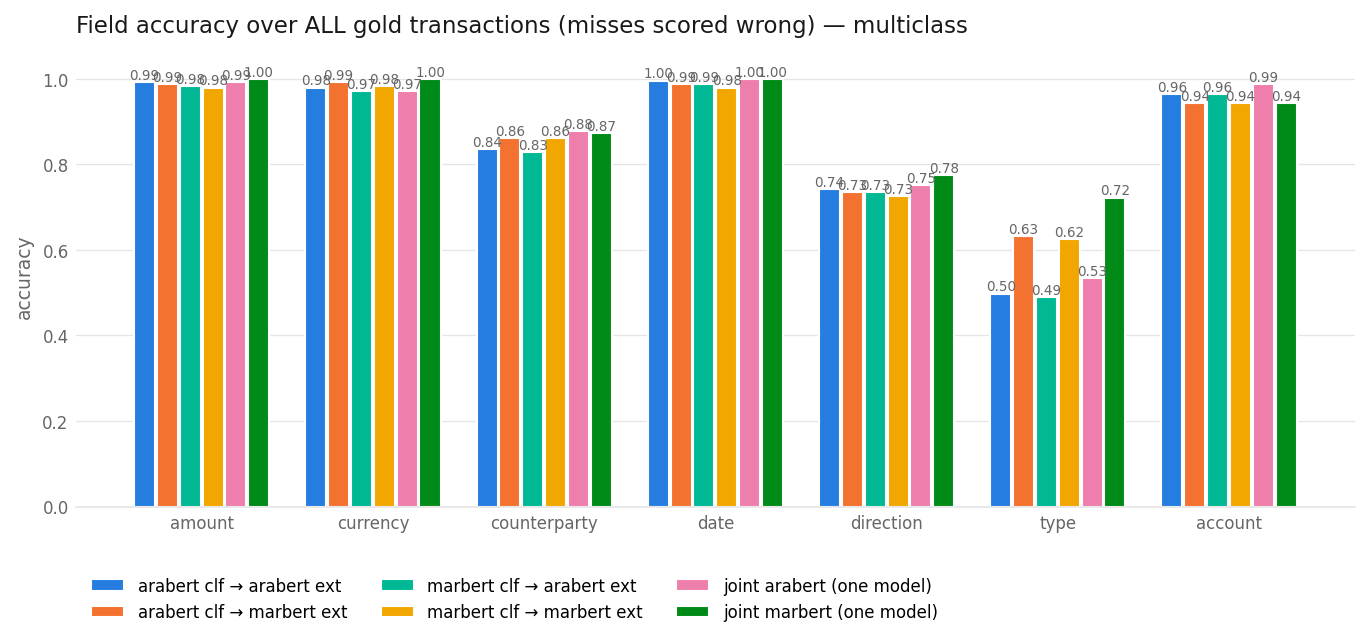

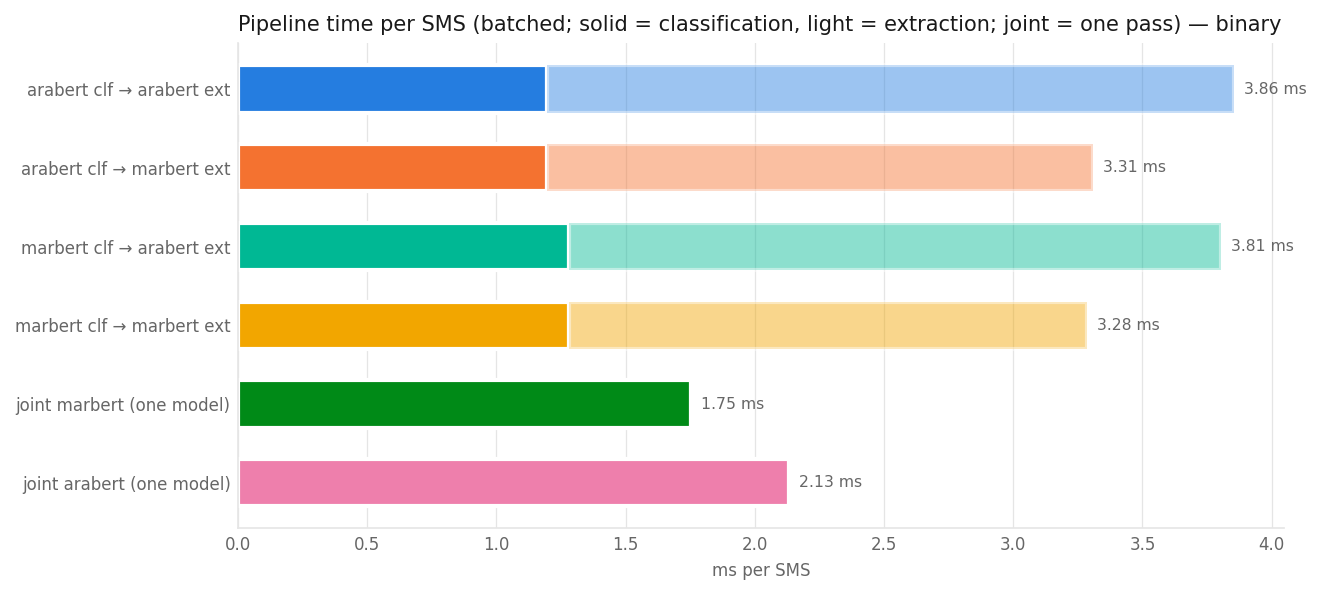

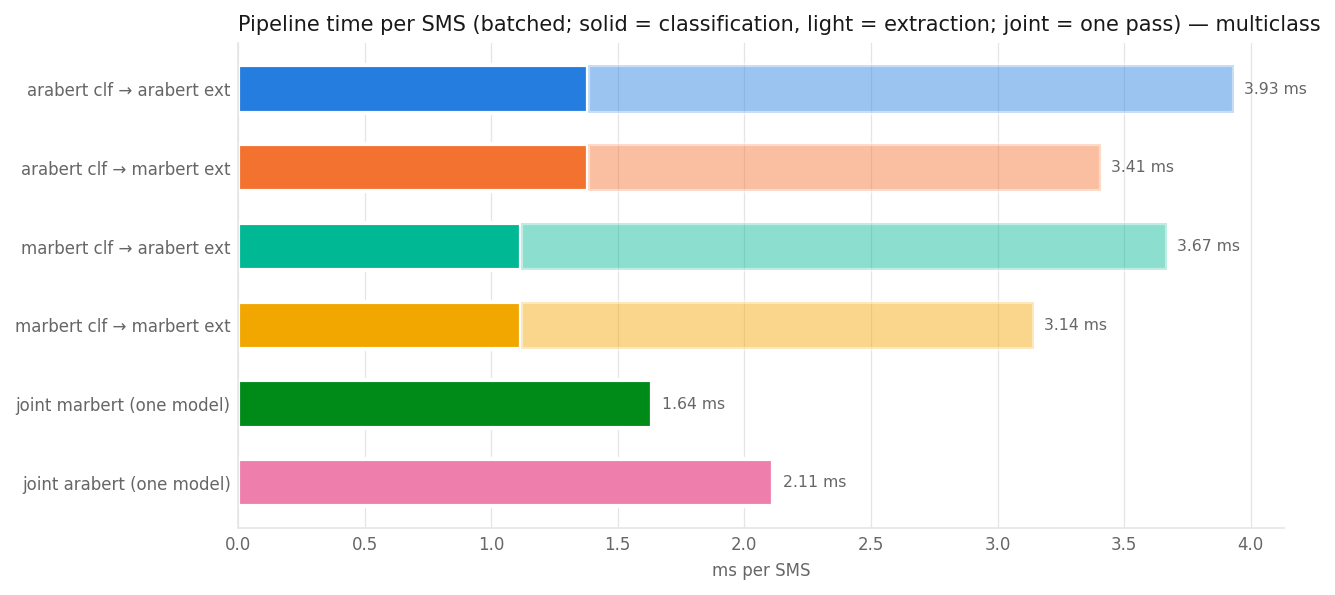

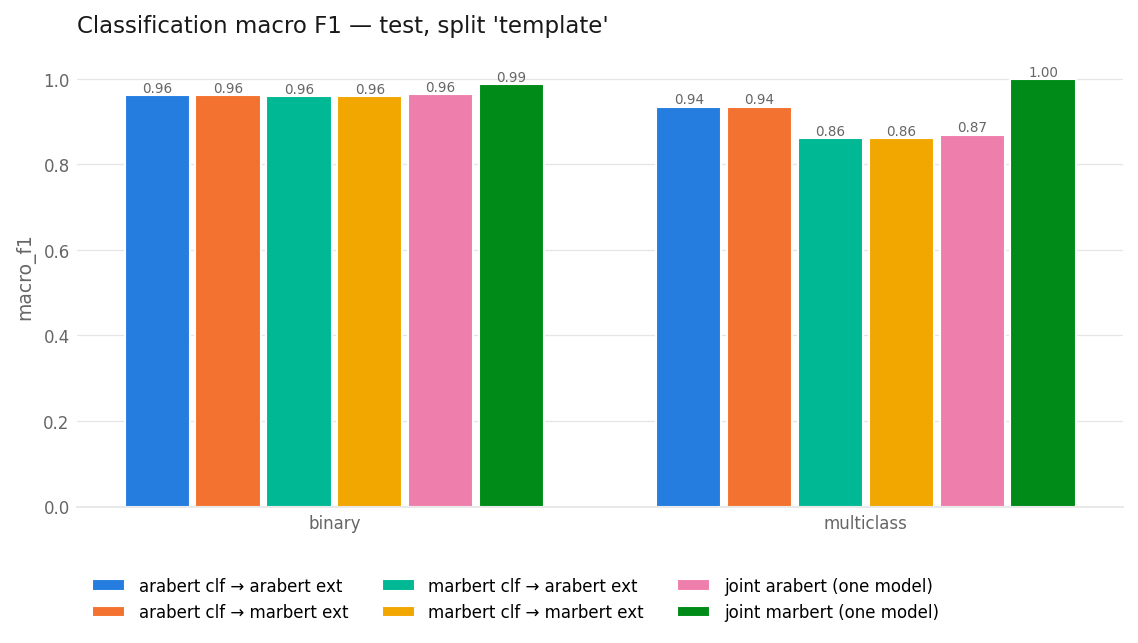

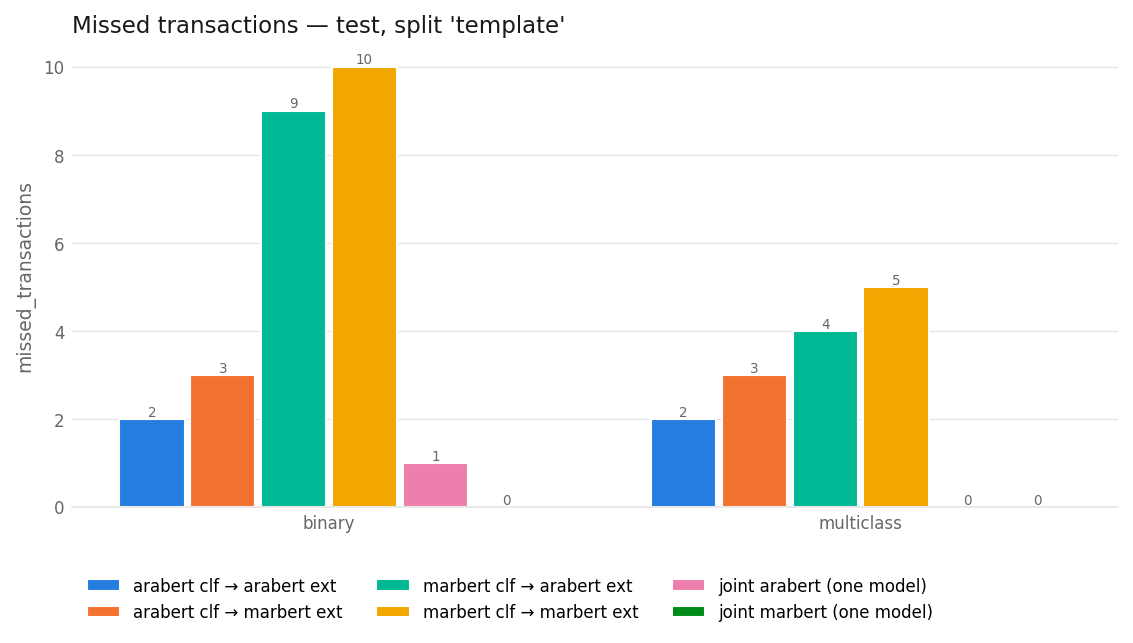

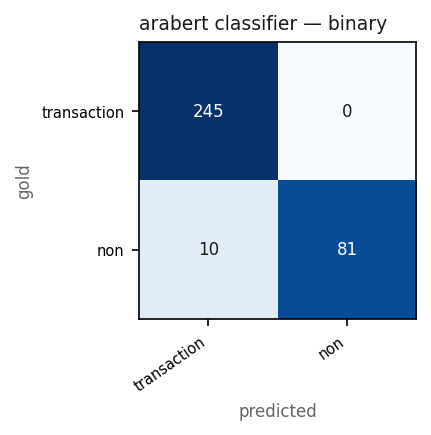

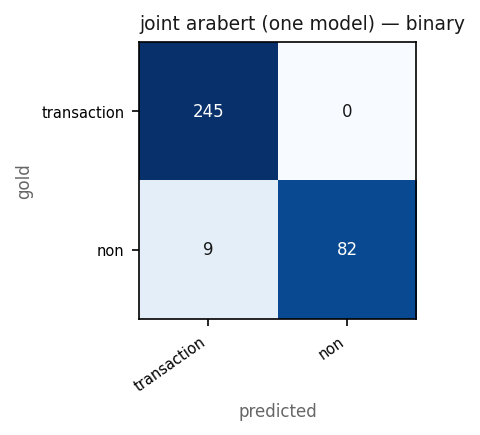

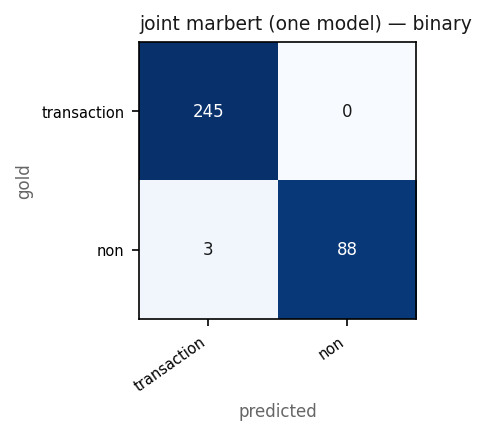

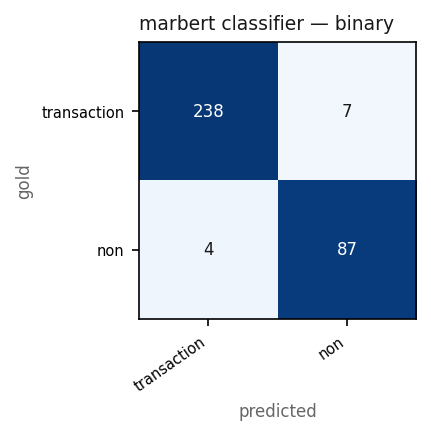

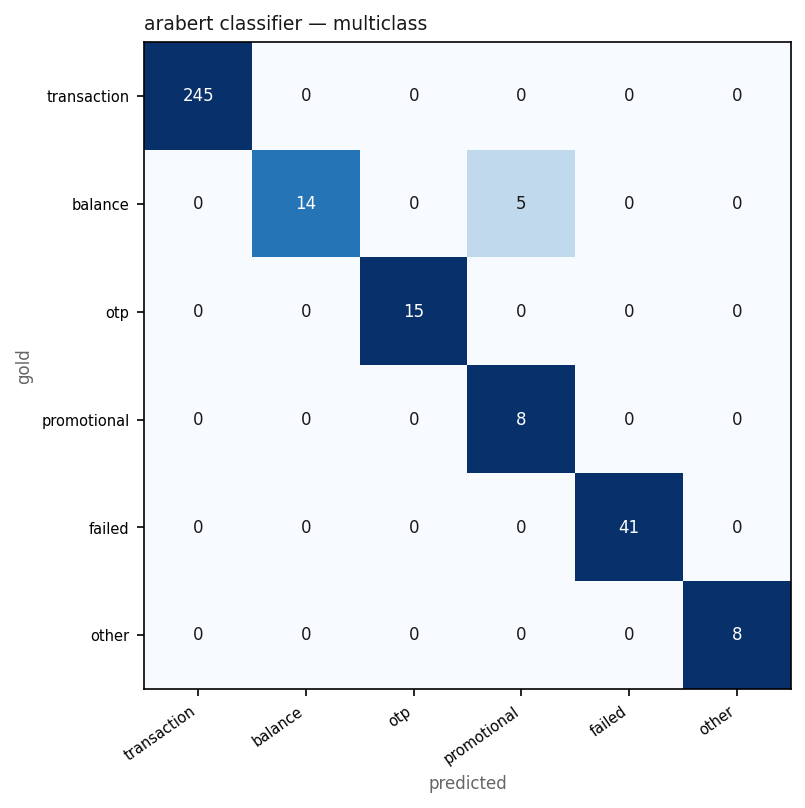

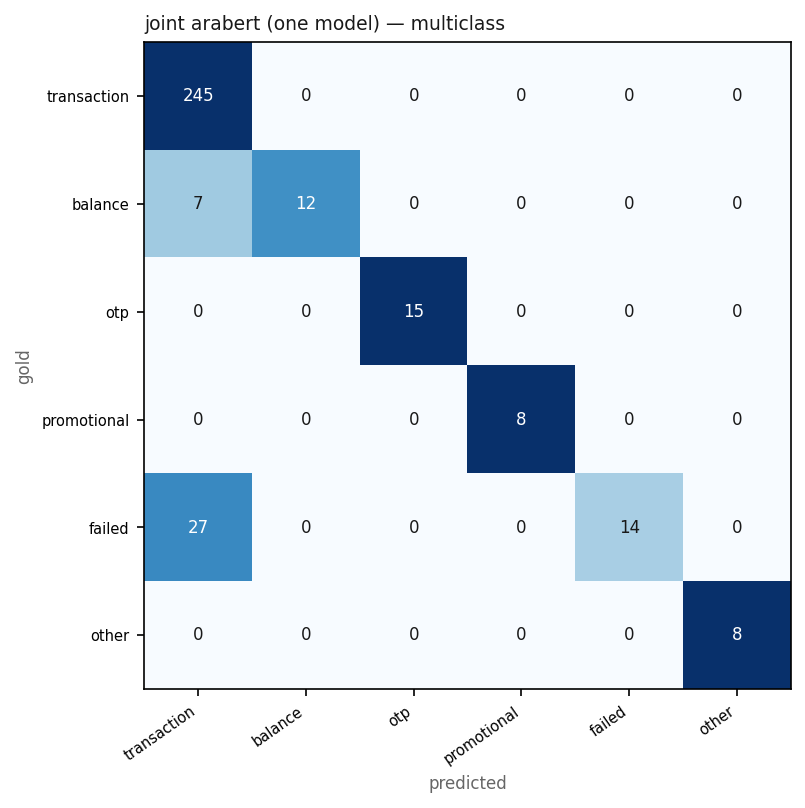

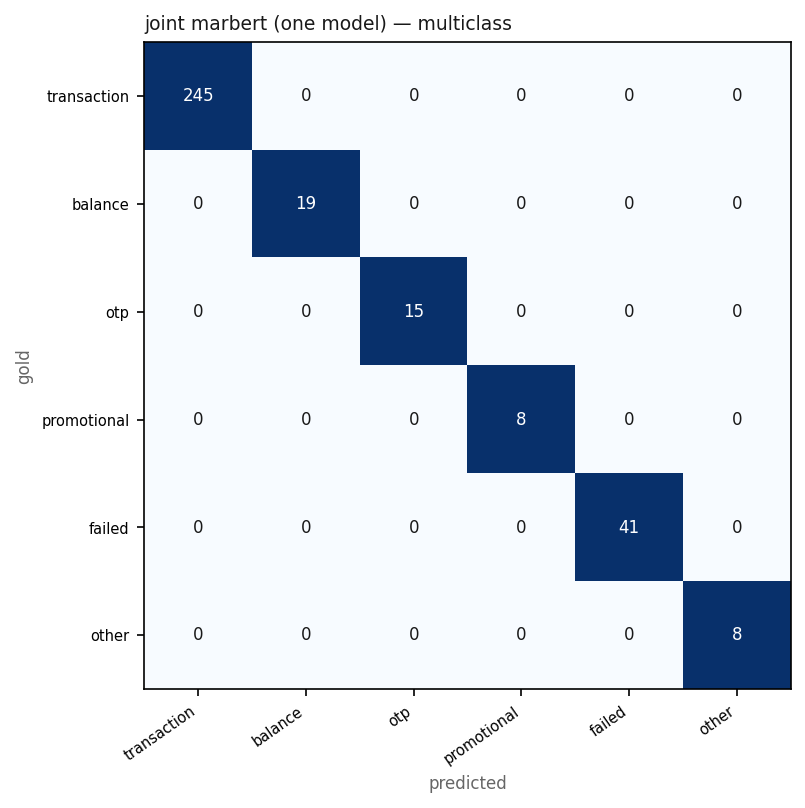

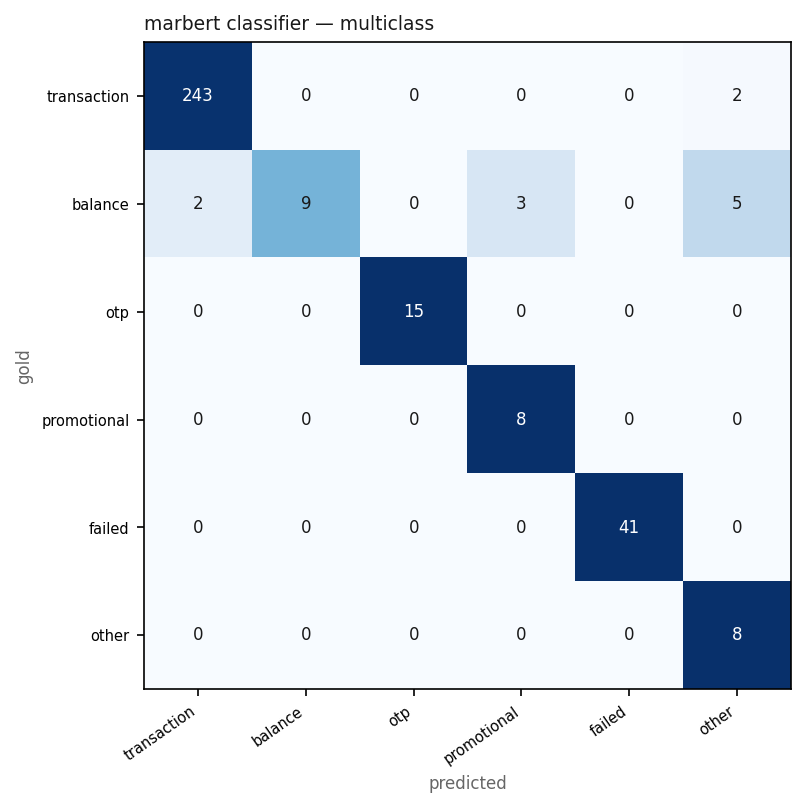

In [24]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]

bench('compare-new', '--splits', SPL)
base = os.path.join(os.environ['SMS_V2_OUTPUT'], 'results', SPL, 'summary_new')
display(Markdown(open(os.path.join(base, 'REPORT_NEW.md'), encoding='utf-8').read()))
for png in sorted(glob.glob(os.path.join(base, 'charts', '*.png'))):
    display(Image(png, width=760))
for png in sorted(glob.glob(os.path.join(base, 'confusion_matrices', '*.png'))):
    display(Image(png, width=380))

### E4. Summary of the latest end-to-end experiments

One compact view of every **finished** end-to-end workflow on `SPLIT`: Experiment 1 combinations
(classifier → transformer extractor), Experiment 2 joint models, and the existing classifier → v1 extractor
runs as reference. Read-only (the same numbers as `REPORT_NEW.md`, straight from each run's `metrics.json`);
re-run any time after more runs finish.

In [25]:
assert 'bench' in globals(), 'Run sections 0 and 1 first (after every connect / disconnect).'
SPL = globals().get('SPLIT') or SPLITS[0]

# E4 summary of the latest end-to-end experiments (reads finished runs only; trains nothing)
import importlib
from evaluation import compare_new
importlib.reload(compare_new)
status, extractors, pipelines, classification, _ = compare_new.collect(SPL)

pd.set_option('display.max_columns', None, 'display.width', 250)
r3 = lambda df: df.round(3)
todo = [s for s in status if s['state'] != 'done']
display(Markdown(f'**split `{SPL}`**: {len(status) - len(todo)} of {len(status)} new runs finished, '
                 f'{len(pipelines)} end-to-end workflows scored'))

if not pipelines:
    print('no finished end-to-end workflow yet: run E1.1-E1.3 and/or E2 first')
else:
    p = pd.DataFrame(pipelines)
    KIND = {'combo': 'Exp 1 combo', 'joint': 'Exp 2 joint', 'ref': 'existing (v1 ext)'}
    p['kind'] = p['kind'].map(KIND)
    p = p.sort_values(['experiment', 'e2e_exact_f1'], ascending=[True, False])

    # ---- headline: full-record exact P/R/F1 + error counts, best first per experiment
    head = ['experiment', 'kind', 'workflow', 'e2e_exact_precision', 'e2e_exact_recall', 'e2e_exact_f1',
            'core_record_exact', 'missed_transactions', 'missed_by_stage1', 'missed_no_amount', 'false_records']
    display(Markdown('#### End to end: full-record exact match (best first)'))
    display(r3(p[[c for c in head if c in p]]).reset_index(drop=True))

    # ---- winner per experiment, and how far each Exp 1/2 workflow is from the existing reference
    display(Markdown('#### Best workflow per experiment'))
    for exp, g in p.groupby('experiment', sort=False):
        b = g.iloc[0]
        ref = g[g.kind == KIND['ref']]
        vs = (f" | best existing ref: {ref.iloc[0].workflow} {ref.e2e_exact_f1.max():.3f} "
              f"({b.e2e_exact_f1 - ref.e2e_exact_f1.max():+.3f})") if len(ref) else ''
        print(f"{exp:10s} -> {b.workflow} [{b.kind}]  F1 {b.e2e_exact_f1:.3f}  "
              f"P {b.e2e_exact_precision:.3f}  R {b.e2e_exact_recall:.3f}  "
              f"missed {int(b.missed_transactions)}  false {int(b.false_records)}{vs}")

    # ---- per-field accuracy over all gold transactions
    fields = [c for c, _ in compare_new.FIELDS if c in p]
    display(Markdown('#### Field accuracy over all gold transactions (a missed transaction counts as wrong)'))
    display(r3(p[['experiment', 'workflow'] + fields + ['counterparty_f1']]
               .rename(columns=dict(compare_new.FIELDS))).reset_index(drop=True))

    # ---- false records by the true class of the message that produced them
    fr = pd.DataFrame([{'experiment': r['experiment'], 'workflow': r['workflow'], **(r['false_records_by_class'] or {})}
                       for r in pipelines]).fillna(0)
    if fr.shape[1] > 2:
        display(Markdown('#### False records by true class'))
        num = fr.columns[2:]
        fr[num] = fr[num].astype(int)
        display(fr.reset_index(drop=True))

    # ---- latency (ms per SMS)
    lat = [c for c in ('classification_ms', 'extraction_ms', 'pipeline_ms', 'live_pipeline_ms',
                       'live_agreement') if c in p]
    display(Markdown('#### Latency, ms per SMS (batch; `live_*` = one SMS at a time, median)'))
    display(p[['experiment', 'workflow'] + lat].round(2).reset_index(drop=True))

# ---- class decision of every workflow
if classification:
    display(Markdown('#### Stage 1 / class head on the test set'))
    display(r3(pd.DataFrame(classification)).reset_index(drop=True))

# ---- standalone extractors (perfect Stage 1)
if extractors:
    display(Markdown('#### Extractors alone (gold transactions, perfect Stage 1)'))
    display(r3(pd.DataFrame(extractors)).reset_index(drop=True))

if todo:
    display(Markdown('#### Not finished yet'))
    display(pd.DataFrame(todo))


**split `template`**: 18 of 18 new runs finished, 16 end-to-end workflows scored

#### End to end: full-record exact match (best first)

,experiment,kind,workflow,e2e_exact_precision,e2e_exact_recall,e2e_exact_f1,core_record_exact,missed_transactions,missed_by_stage1,missed_no_amount,false_records
0,binary,Exp 2 joint,joint marbert (one model),0.496,0.502,0.499,0.661,0,0,0,3
1,binary,Exp 1 combo,arabert clf → marbert ext,0.425,0.437,0.431,0.604,3,0,3,10
2,binary,Exp 1 combo,marbert clf → marbert ext,0.435,0.424,0.430,0.592,10,7,3,4
3,binary,Exp 2 joint,joint arabert (one model),0.392,0.392,0.392,0.535,1,0,1,1
4,binary,Exp 1 combo,arabert clf → arabert ext,0.341,0.351,0.346,0.555,2,0,2,9
5,binary,Exp 1 combo,marbert clf → arabert ext,0.335,0.327,0.331,0.531,9,7,2,3
6,binary,existing (v1 ext),arabert clf → v1 ext (existing),0.298,0.310,0.304,0.416,0,0,0,10
7,binary,existing (v1 ext),marbert clf → v1 ext (existing),0.285,0.282,0.283,0.388,7,7,0,4
8,multiclass,Exp 2 joint,joint marbert (one model),0.543,0.543,0.543,0.616,0,0,0,0
9,multiclass,Exp 1 combo,arabert clf → marbert ext,0.442,0.437,0.439,0.604,3,0,3,0


#### Best workflow per experiment

binary     -> joint marbert (one model) [Exp 2 joint]  F1 0.499  P 0.496  R 0.502  missed 0  false 3 | best existing ref: arabert clf → v1 ext (existing) 0.304 (+0.195)
multiclass -> joint marbert (one model) [Exp 2 joint]  F1 0.543  P 0.543  R 0.543  missed 0  false 0 | best existing ref: arabert clf → v1 ext (existing) 0.310 (+0.233)


#### Field accuracy over all gold transactions (a missed transaction counts as wrong)

... (5 outputs left out)

#### Stage 1 / class head on the test set

,experiment,workflow,accuracy,macro_precision,macro_recall,macro_f1,transaction_precision,transaction_recall
0,binary,"arabert classifier (Exp 1, shared by its 2 com...",0.970,0.980,0.945,0.961,0.961,1.000
1,binary,"marbert classifier (Exp 1, shared by its 2 com...",0.967,0.955,0.964,0.959,0.983,0.971
2,binary,joint marbert (one model),0.991,0.994,0.984,0.989,0.988,1.000
3,binary,joint arabert (one model),0.973,0.982,0.951,0.965,0.965,1.000
4,multiclass,"arabert classifier (Exp 1, shared by its 2 com...",0.985,0.936,0.956,0.935,1.000,1.000
5,multiclass,"marbert classifier (Exp 1, shared by its 2 com...",0.964,0.875,0.911,0.862,0.992,0.992
6,multiclass,joint marbert (one model),1.000,1.000,1.000,1.000,1.000,1.000
7,multiclass,joint arabert (one model),0.899,0.980,0.829,0.870,0.878,1.000


#### Extractors alone (gold transactions, perfect Stage 1)

,extractor,n,amount_acc,currency_acc,counterparty_precision,counterparty_recall,counterparty_f1,date_acc,datetime_acc,direction_acc,type_acc,account_last4_acc,full_record_exact,core_record_exact,ms_per_sms,best_epoch,device
0,v1_sklearn,245,0.967,0.984,0.920,0.508,0.655,0.820,0.820,0.804,0.600,0.943,0.310,0.416,10.327,NaN,NaN
1,marbert,245,0.988,0.992,0.849,0.867,0.858,0.988,0.988,0.735,0.633,0.943,0.437,0.604,2.780,10.0,cuda
2,arabert,245,0.992,0.980,0.796,0.818,0.807,0.996,0.996,0.743,0.498,0.963,0.351,0.555,3.502,8.0,cuda
